<center><h1>Liu_Yanchen_HW4</h1></center>
<br>
<br>

Name: Yanchen Liu
<br>
Github Username: jamesnulliu

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

Part 1 is the feature-creation code submitted with Homework 3, repeated here so that this
notebook runs end to end on its own. Each of the 88 AReM instances is 6 time series of 480
samples; this part turns every instance into a single row of time-domain features.

### (a) Obtain Data

Import packages

In [1]:
import os
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, auc,
                             confusion_matrix, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler, label_binarize

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
# Complete separation of the training classes is a *finding* of this notebook, discussed at
# length in 2(a)vi; the repeated statsmodels warning about it is silenced here and the
# diagnostics are reported explicitly instead.
warnings.filterwarnings("ignore", message=".*Perfect separation.*")
warnings.filterwarnings("ignore", message=".*Maximum Likelihood optimization failed.*")

pd.set_option("display.precision", 4)
pd.set_option("display.width", 170)

BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
})

RANDOM_STATE = 42

Get the AReM Data Set

Paths are **relative** and use `/` separators. Four of the 88 files need the minor cleaning
mentioned in the assignment footnote, and the reader repairs all four automatically:
`bending2/dataset4.csv` is whitespace- rather than comma-delimited, `cycling/dataset9.csv` and
`cycling/dataset14.csv` end their last row with a stray comma, and `sitting/dataset8.csv` is
missing the sample at *t* = 13500 ms (it is restored by linear interpolation in time).

In [2]:
AREM_DIR = "../data/Homework 3, 4 Data/AReM"

ACTIVITIES = ["bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking"]
SERIES = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]
N_TIME = 480
CLOCK_MS = 250


def read_instance(path):
    """Read one AReM dataset file, repairing the four known formatting defects."""
    rows = []
    with open(path, "r") as fh:
        for line in fh:
            line = line.strip()
            if not line or line.startswith("#"):
                continue
            fields = [tok for tok in re.split(r"[,\s]+", line) if tok != ""]
            rows.append([float(tok) for tok in fields])

    df = pd.DataFrame(rows, columns=["time"] + SERIES)
    grid = np.arange(N_TIME) * CLOCK_MS
    if len(df) != N_TIME or not np.array_equal(df["time"].to_numpy(), grid):
        df = (df.set_index("time")
                .reindex(grid)
                .interpolate(method="index", limit_direction="both")
                .rename_axis("time")
                .reset_index())
    return df[SERIES]


def load_arem(root=AREM_DIR):
    """Load all 88 instances; return the series, their labels and the test-set mask."""
    instances, labels, is_test = [], [], []
    for activity in ACTIVITIES:
        folder = os.path.join(root, activity)
        files = sorted(os.listdir(folder), key=lambda f: int(re.search(r"\d+", f).group()))
        for fname in files:
            idx = int(re.search(r"\d+", fname).group())
            instances.append(read_instance(os.path.join(folder, fname)))
            labels.append(activity)
            is_test.append(idx <= (2 if activity.startswith("bending") else 3))
    return instances, np.array(labels), np.array(is_test)


instances, labels, is_test = load_arem()
print(f"instances loaded : {len(instances)}")
print(f"shape of each    : {set(df.shape for df in instances)}")
print(f"missing values   : {sum(int(df.isna().sum().sum()) for df in instances)}")

instances loaded : 88
shape of each    : {(480, 6)}
missing values   : 0


### (b) Splitting Data

Datasets 1 and 2 of `bending1` and `bending2`, and datasets 1, 2 and 3 of the other five
folders, are the **test set**; the remaining 69 instances are the **train set**.

In [3]:
train_idx = np.flatnonzero(~is_test)
test_idx = np.flatnonzero(is_test)

y_train_multi, y_test_multi = labels[train_idx], labels[test_idx]
# Binary task of question 2(a): bending (bending1 or bending2) against everything else.
y_binary = np.where(np.char.startswith(labels.astype(str), "bending"), 1, 0)
y_train, y_test = y_binary[train_idx], y_binary[test_idx]

split = pd.DataFrame({"activity": labels, "split": np.where(is_test, "test", "train")})
counts = (split.groupby(["activity", "split"]).size().unstack(fill_value=0)
          .reindex(ACTIVITIES)[["train", "test"]])
counts["total"] = counts.sum(axis=1)
counts.loc["ALL"] = counts.sum()
print(counts.to_string())
print(f"\nbinary labels  train: {y_train.sum()} bending / {(1 - y_train).sum()} other"
      f"   test: {y_test.sum()} bending / {(1 - y_test).sum()} other")

split     train  test  total
activity                    
bending1      5     2      7
bending2      4     2      6
cycling      12     3     15
lying        12     3     15
sitting      12     3     15
standing     12     3     15
walking      12     3     15
ALL          69    19     88

binary labels  train: 9 bending / 60 other   test: 4 bending / 15 other


### (c) Feature Extraction

Each of the 6 series is split into $l$ near-equal segments and summarised by 7 statistics
(minimum, maximum, mean, median, standard deviation, first and third quartile), giving $42l$
features per instance. With $l = 1$ this is the 42-feature matrix of Homework 3.

**Splitting changes the number of features, never the number of instances** — there are always
69 training and 19 test rows.

Homework 3 question 1(c)iv selected **minimum, mean and maximum** as the three most important
statistics, and those are the three used in the scatter plots of 2(a)i and 2(a)ii below.

In [4]:
STATS = ["min", "max", "mean", "median", "std", "q1", "q3"]
CHOSEN_STATS = ["min", "mean", "max"]      # from HW3 question 1(c)iv


def _stats_block(arr):
    return [arr.min(), arr.max(), arr.mean(), np.median(arr),
            arr.std(ddof=1), np.percentile(arr, 25), np.percentile(arr, 75)]


def extract_features(instance_list, l=1):
    """Split each of the 6 series into `l` near-equal parts, take 7 statistics of each."""
    rows, columns = [], None
    for df in instance_list:
        row, cols = [], []
        for s in SERIES:
            for part_idx, part in enumerate(np.array_split(df[s].to_numpy(), l), start=1):
                row.extend(_stats_block(part))
                suffix = "" if l == 1 else f"_{part_idx}"
                cols.extend(f"{stat}_{s}{suffix}" for stat in STATS)
        rows.append(row)
        columns = cols
    return pd.DataFrame(rows, columns=columns)


train_instances = [instances[i] for i in train_idx]
test_instances = [instances[i] for i in test_idx]

L_GRID = list(range(1, 21))
F_train = {l: extract_features(train_instances, l) for l in L_GRID}
F_test = {l: extract_features(test_instances, l) for l in L_GRID}

print("features per instance, by number of segments l:")
print(pd.DataFrame({"l": L_GRID,
                    "n_features": [F_train[l].shape[1] for l in L_GRID],
                    "n_train_rows": [F_train[l].shape[0] for l in L_GRID],
                    "n_test_rows": [F_test[l].shape[0] for l in L_GRID]}
                   ).set_index("l").T.to_string())
F_train[1].head()

features per instance, by number of segments l:
l             1   2    3    4    5    6    7    8    9    10   11   12   13   14   15   16   17   18   19   20
n_features    42  84  126  168  210  252  294  336  378  420  462  504  546  588  630  672  714  756  798  840
n_train_rows  69  69   69   69   69   69   69   69   69   69   69   69   69   69   69   69   69   69   69   69
n_test_rows   19  19   19   19   19   19   19   19   19   19   19   19   19   19   19   19   19   19   19   19


,min_avg_rss12,max_avg_rss12,mean_avg_rss12,median_avg_rss12,std_avg_rss12,q1_avg_rss12,q3_avg_rss12,min_var_rss12,max_var_rss12,mean_var_rss12,...,std_avg_rss23,q1_avg_rss23,q3_avg_rss23,min_var_rss23,max_var_rss23,mean_var_rss23,median_var_rss23,std_var_rss23,q1_var_rss23,q3_var_rss23
0,35.00,47.40,43.9545,44.33,1.5588,43.00,45.00,0.0,1.70,0.4263,...,1.9996,35.3625,36.50,0.0,1.79,0.4933,0.43,0.5135,0.00,0.94
1,33.00,47.75,42.1798,43.50,3.6707,39.15,45.00,0.0,3.00,0.6960,...,3.8494,30.4575,36.33,0.0,2.18,0.6135,0.50,0.5243,0.00,1.00
2,33.00,45.75,41.6781,41.75,2.2435,41.33,42.75,0.0,2.83,0.5360,...,2.4110,28.4575,31.25,0.0,1.79,0.3833,0.43,0.3892,0.00,0.50
3,37.00,48.00,43.4550,43.25,1.3861,42.50,45.00,0.0,1.58,0.3781,...,2.4889,22.2500,24.00,0.0,5.26,0.6796,0.50,0.6225,0.43,0.87
4,36.25,48.00,43.9691,44.50,1.6184,43.31,44.67,0.0,1.50,0.4131,...,3.3183,20.5000,23.75,0.0,2.96,0.5553,0.49,0.4878,0.00,0.83


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

The task is to separate **bending** (`bending1` + `bending2`) from the five other activities.
Throughout this section "logistic regression" means an *unpenalised* fit: following the
assignment footnote, the $\mathcal{L}_2$ penalty is removed by setting the budget
$C = 10^{6}$, which is numerically better behaved than `penalty=None` on nearly separable data.

In [5]:
def plain_logit():
    """Logistic regression with the L2 penalty switched off (C -> infinity)."""
    return LogisticRegression(penalty="l2", C=1e6, solver="liblinear", max_iter=1000)

#### i. Plots

Scatter plots of the three features chosen in Homework 3 1(c)iv — minimum, mean and maximum —
extracted from **time series 1, 2 and 6** of each instance, i.e. `avg_rss12`, `var_rss12` and
`var_rss23`. Colour distinguishes bending from the other activities. All 88 instances are
shown, as the question asks for a picture of the data rather than a fitted model.

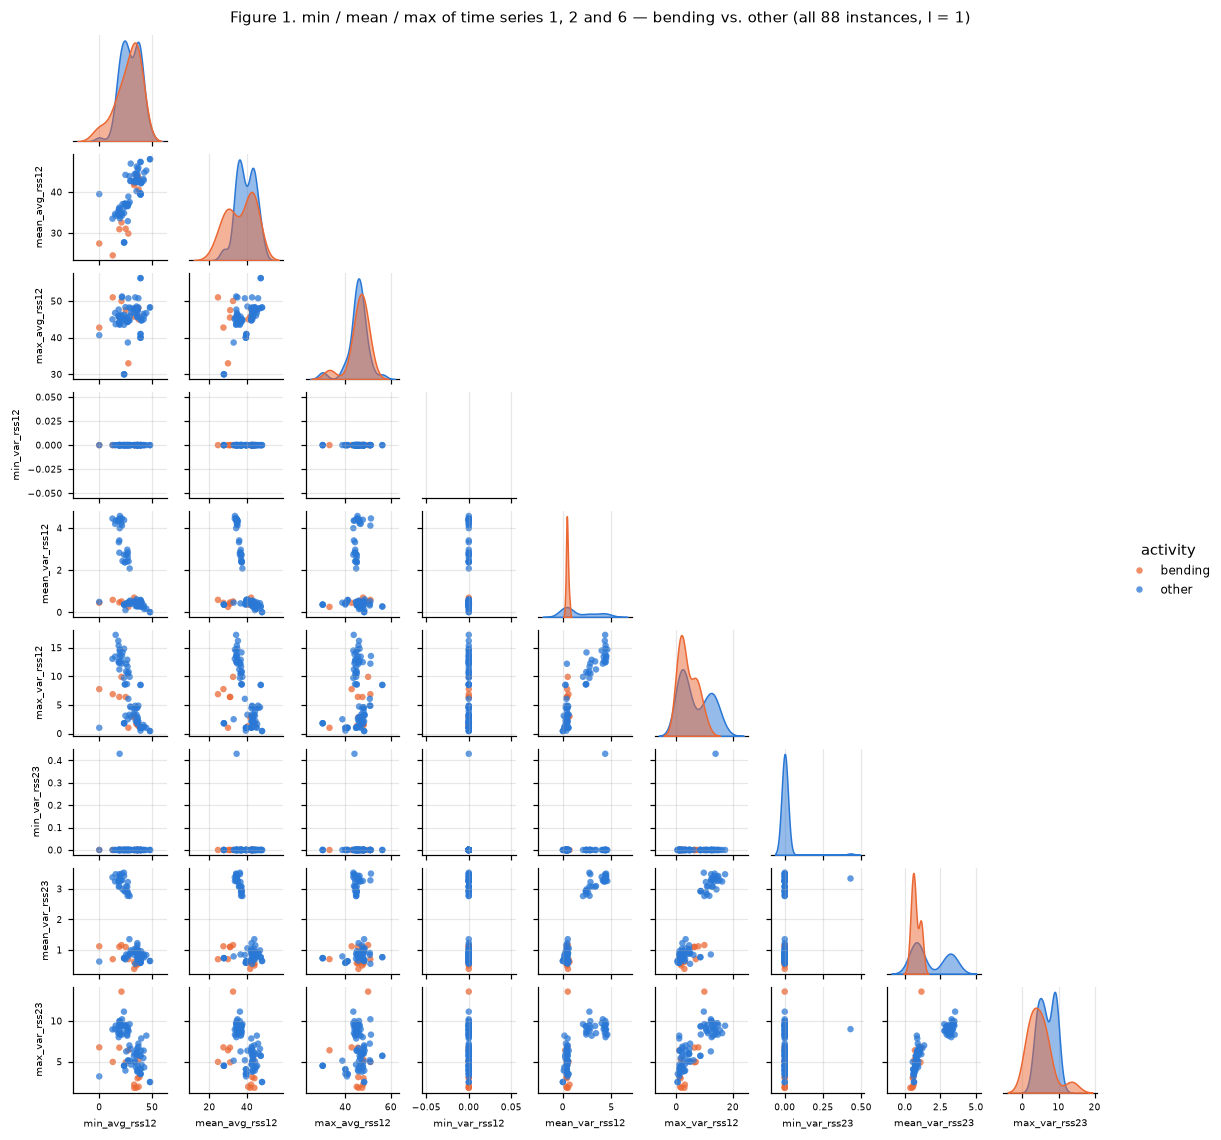

constant among these nine features: ['min_var_rss12'] 

single-feature separability for bending vs. other:
                   AUC  bending_mean  other_mean  separating_power
mean_var_rss23  0.2133        0.7506      1.7716            0.5733
max_var_rss23   0.2692        4.8000      6.7500            0.4615
max_var_rss12   0.3621        3.9569      6.6945            0.2759
mean_var_rss12  0.3774        0.4512      1.6338            0.2451
mean_avg_rss12  0.3867       36.5512     39.3275            0.2267
max_avg_rss12   0.5908       45.9477     45.3908            0.1815
min_avg_rss12   0.4656       27.2885     29.3397            0.0687
min_var_rss23   0.4933        0.0000      0.0057            0.0133
min_var_rss12      NaN        0.0000      0.0000               NaN

for reference, the best feature from time series 5 (avg_rss23), which is NOT plotted here:
  max_avg_rss23: AUC = 0.9605
  mean_avg_rss23: AUC = 0.9251


In [6]:
TS_126 = [SERIES[0], SERIES[1], SERIES[5]]       # time series 1, 2 and 6
cols_126 = [f"{st}_{s}" for s in TS_126 for st in CHOSEN_STATS]

plot_df = extract_features(instances, l=1)[cols_126].copy()
plot_df["activity"] = np.where(y_binary == 1, "bending", "other")

g = sns.pairplot(plot_df, vars=cols_126, hue="activity", corner=True,
                 palette={"bending": ORANGE, "other": BLUE},
                 plot_kws={"s": 18, "alpha": 0.75, "linewidth": 0},
                 diag_kws={"common_norm": False, "alpha": 0.5}, height=1.15)
for ax in g.axes.flat:
    if ax is not None:
        ax.tick_params(labelsize=6)
        ax.set_xlabel(ax.get_xlabel(), fontsize=6.5)
        ax.set_ylabel(ax.get_ylabel(), fontsize=6.5)
g.figure.suptitle("Figure 1. min / mean / max of time series 1, 2 and 6 — bending vs. other "
                  "(all 88 instances, l = 1)", y=1.005, fontsize=10)
plt.show()

const_cols = [c for c in cols_126 if plot_df[c].std(ddof=1) == 0]
print("constant among these nine features:", const_cols, "\n")

# How well does each of the nine separate bending on its own? AUC < 0.5 simply means the
# relationship runs the other way, so |AUC - 0.5| * 2 is the honest measure of separating power.
sep = pd.DataFrame({
    "AUC": [roc_auc_score(y_binary, plot_df[c]) if plot_df[c].std(ddof=1) > 0 else np.nan
            for c in cols_126],
    "bending_mean": [plot_df.loc[y_binary == 1, c].mean() for c in cols_126],
    "other_mean": [plot_df.loc[y_binary == 0, c].mean() for c in cols_126],
}, index=cols_126)
sep["separating_power"] = (sep["AUC"] - 0.5).abs() * 2
print("single-feature separability for bending vs. other:")
print(sep.sort_values("separating_power", ascending=False).round(4).to_string())
print("\nfor reference, the best feature from time series 5 (avg_rss23), which is NOT plotted here:")
_ref = extract_features(instances, l=1)
for c in ["max_avg_rss23", "mean_avg_rss23"]:
    print(f"  {c}: AUC = {roc_auc_score(y_binary, _ref[c]):.4f}")

These nine features are, individually, **weak separators**, and it is worth saying so plainly:
it is easy to look at a nine-panel matrix and see structure that is not there. The orange and
blue clouds overlap substantially in every single panel.

What signal there is lives in the **variance channels, and it points downwards**:

- **Bending means low variance.** A bending person moves slowly and smoothly, so the RSS variance
  stays small, while cycling and walking make it jump. `mean_var_rss23` averages 0.75 for bending
  against 1.77 for the rest and is the strongest of the nine (AUC 0.213, i.e. 0.787 once the
  direction is flipped); `max_var_rss23` follows at 4.80 against 6.75.
- **The `avg_rss12` statistics barely separate at all** — `mean_avg_rss12` reaches AUC 0.387 and
  `min_avg_rss12` only 0.466, which is almost exactly a coin flip. Time series 1 on its own says
  very little about bending.
- **`min_var_rss12` is exactly 0 for all 88 instances**, so its row and column of the matrix
  collapse onto a single line. This was found in Homework 3 1(c)iii: over a two-minute window the
  RSS variance of sensor pair 1-2 always touches zero at some point. `min_var_rss23` is nearly as
  degenerate (AUC 0.493). Both are harmless — standardisation reduces a constant column to zero —
  but they mean that only 7 of these 9 features carry any information.

This matters for reading 2(a)iii-vi later. **No linear boundary drawn in these nine features
would classify the training set cleanly**, yet 2(a)iv finds the classes *completely* separable.
There is no contradiction: that separation is achieved in 13 dimensions chosen from all 42
features, and leans on the `avg_rss23` channel (time series 5), which is not plotted here and is
far more discriminative on its own — `max_avg_rss23` alone reaches AUC 0.961. Separability is a
property of the whole feature space, not something one can read off a single projection of it.

#### ii. Splitted Plots

Each time series is now broken into **two approximately equal halves** ($l = 2$), so each
instance has 12 time series instead of 6. The same nine features are re-extracted from both
halves of time series 1, 2 and 6 and plotted separately, which makes the two halves directly
comparable with Figure 1.

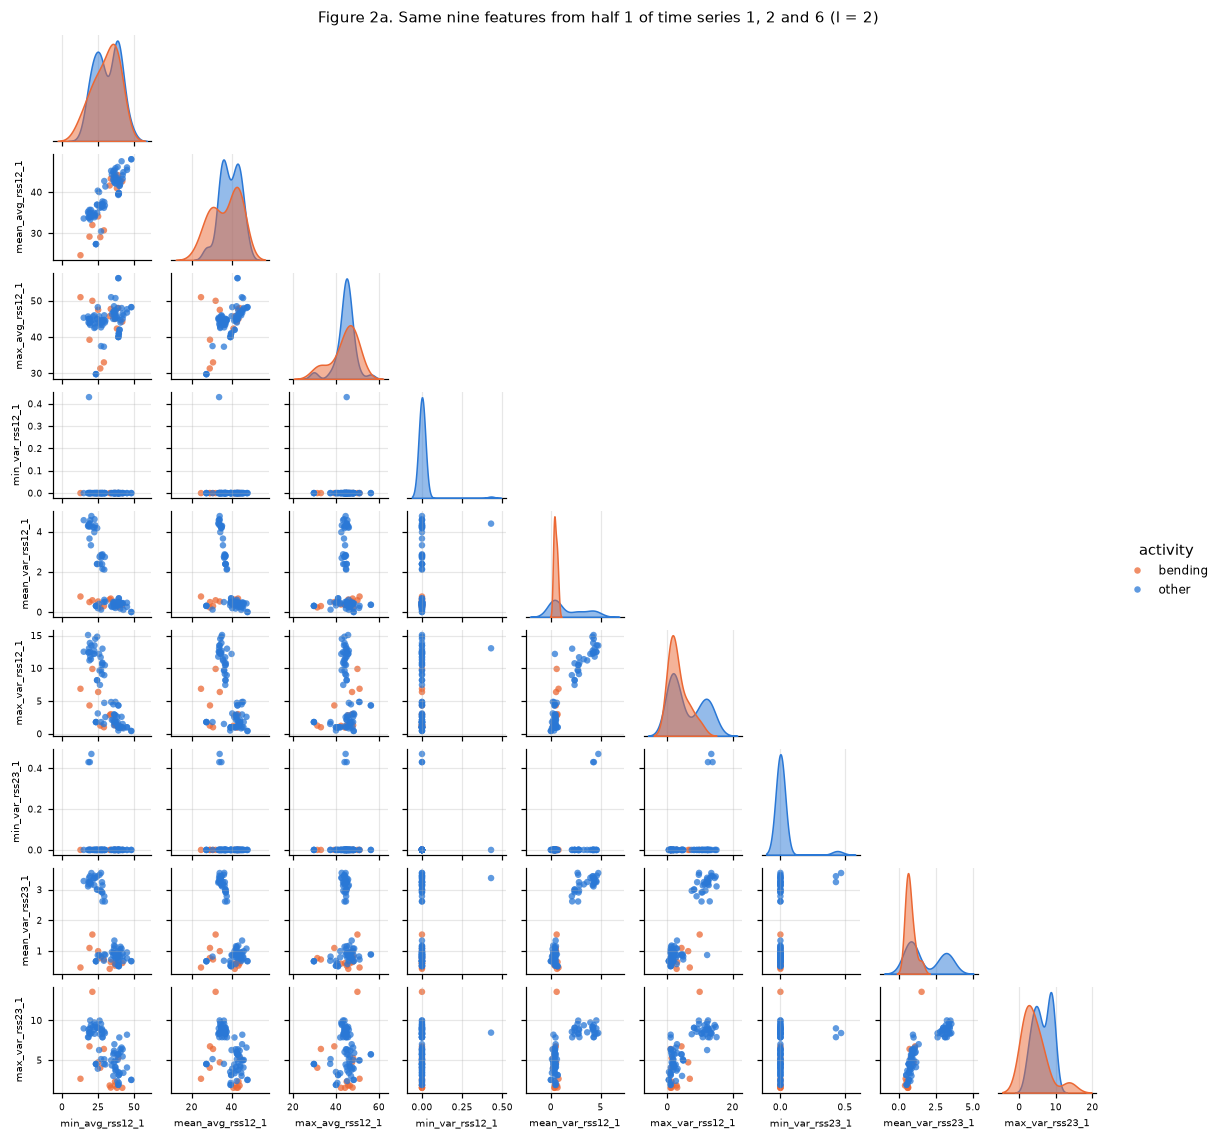

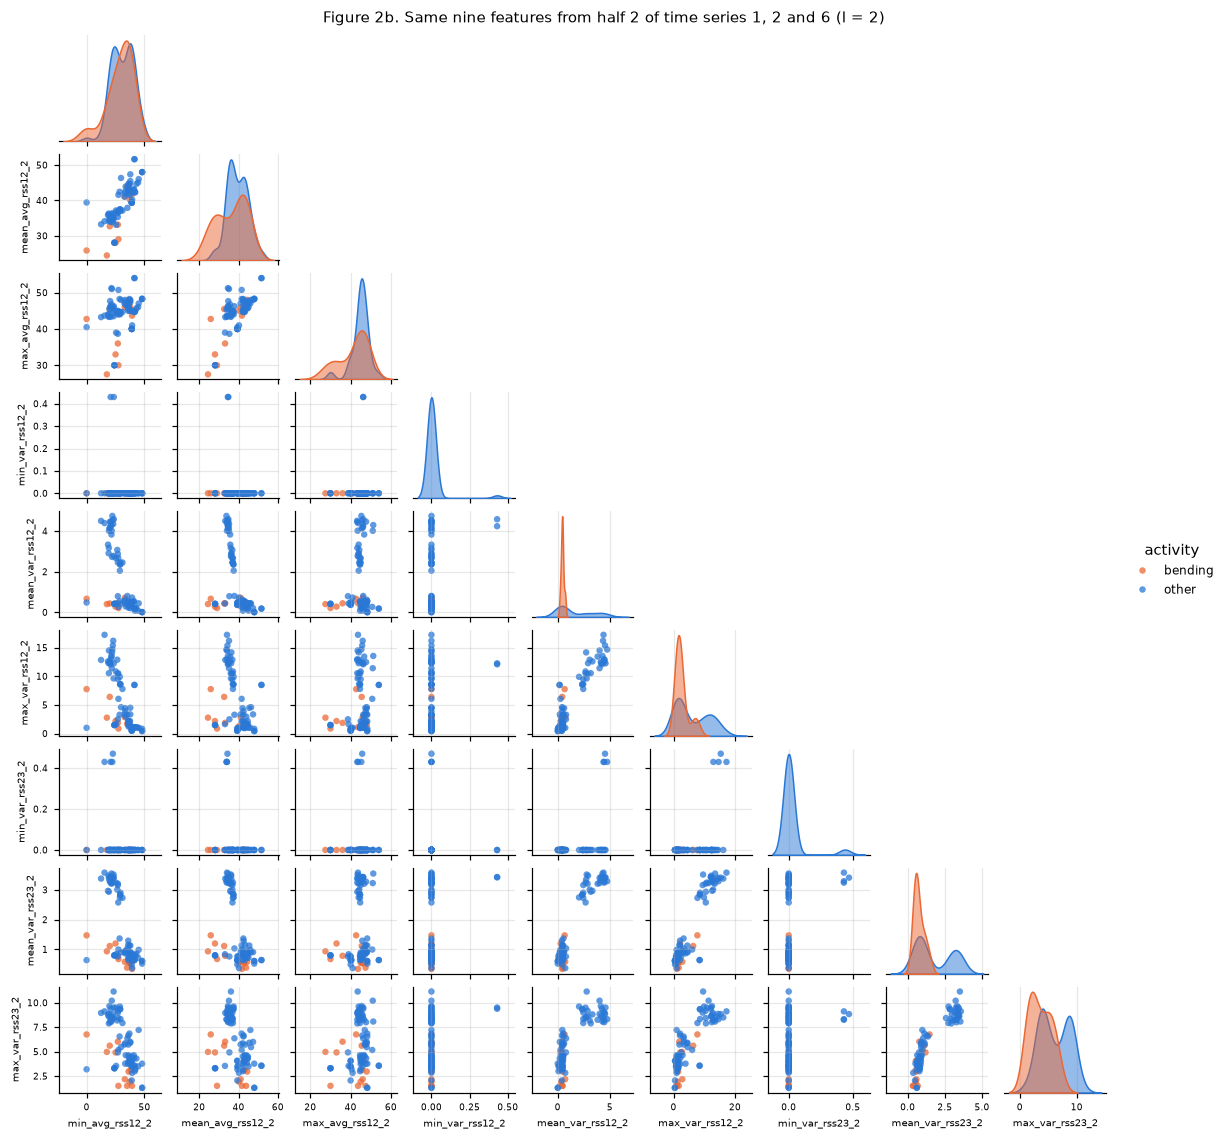

                half1_vs_half2_corr
min_avg_rss12                0.7400
mean_avg_rss12               0.9027
max_avg_rss12                0.5668
min_var_rss12               -0.0163
mean_var_rss12               0.9889
max_var_rss12                0.8910
min_var_rss23                0.2435
mean_var_rss23               0.9807
max_var_rss23                0.7954


In [7]:
plot2 = extract_features(instances, l=2)
plot2_label = np.where(y_binary == 1, "bending", "other")

for half in (1, 2):
    cols_h = [f"{st}_{s}_{half}" for s in TS_126 for st in CHOSEN_STATS]
    d = plot2[cols_h].copy()
    d["activity"] = plot2_label
    g = sns.pairplot(d, vars=cols_h, hue="activity", corner=True,
                     palette={"bending": ORANGE, "other": BLUE},
                     plot_kws={"s": 18, "alpha": 0.75, "linewidth": 0},
                     diag_kws={"common_norm": False, "alpha": 0.5}, height=1.15)
    for ax in g.axes.flat:
        if ax is not None:
            ax.tick_params(labelsize=6)
            ax.set_xlabel(ax.get_xlabel(), fontsize=6.5)
            ax.set_ylabel(ax.get_ylabel(), fontsize=6.5)
    g.figure.suptitle(f"Figure 2{'ab'[half - 1]}. Same nine features from half {half} "
                      f"of time series 1, 2 and 6 (l = 2)", y=1.005, fontsize=10)
    plt.show()

# How much do the two halves actually differ?
comp = pd.DataFrame({
    f"half1_vs_half2_corr": [np.corrcoef(plot2[f"{st}_{s}_1"], plot2[f"{st}_{s}_2"])[0, 1]
                             for s in TS_126 for st in CHOSEN_STATS]},
    index=[f"{st}_{s}" for s in TS_126 for st in CHOSEN_STATS])
print(comp.round(4).to_string())

**No, there is no considerable difference.** Figures 2a and 2b are near-copies of each other
and of Figure 1: the same bending cluster sits in the same place, with the same overlap.

The correlation table explains why, and it separates the three statistics neatly. Across the 88
instances, a feature computed on the first half correlates with the same feature on the second
half at:

- **0.90-0.99 for the means** (`mean_var_rss12` 0.989, `mean_var_rss23` 0.981,
  `mean_avg_rss12` 0.903) — the *level* of each signal is essentially the same in both halves;
- **0.57-0.89 for the maxima** (`max_var_rss12` 0.891, `max_var_rss23` 0.795,
  `max_avg_rss12` 0.567) — noticeably less stable;
- **near zero for the minima of the variance channels** (`min_var_rss23` 0.244 and
  `min_var_rss12` -0.016, the latter being the constant feature).

That gradient is exactly what theory predicts. These activities are *stationary over the
two-minute recording* — a person cycling at second 10 is still cycling at second 110 — so each
half is effectively an independent sample of the same distribution. A **mean** averages 240
points and is therefore reproduced almost exactly; an **extreme order statistic** depends on a
single lucky sample and is not. The class information lives in the stable location features,
which is why the scatter plots look unchanged.

The one systematic change is that splitting **doubles the number of features while leaving the
88 instances untouched**. At $l = 2$ this is harmless; by $l = 20$ there are 840 features for
69 training instances, and the risk of overfitting is exactly what the cross-validation in
2(a)iii has to control.

#### iii. Time Series Segments

Each training time series is broken into $l \in \{1, 2, \dots, 20\}$ segments, and logistic
regression is used for the binary problem. Backward selection is done with
`sklearn.feature_selection.RFE` — the alternative the assignment explicitly allows in place of
pruning by $p$-values — and 5-fold cross-validation chooses the pair $(l, p)$, where $p$ is the
number of features kept.

**The right and the wrong way to cross-validate here.**

The *wrong* way is to run RFE once on the whole training set, keep the $p$ winning features, and
only then cross-validate a model built on them. The feature selection would have seen every
validation fold before that fold was used to score the model, so each fold is no longer held
out. The reported accuracy is then optimistically biased, sometimes severely: with 840
candidate features and 69 instances it is easy to find a handful of features that separate
*this particular* training set by chance, and a selection-contaminated CV will happily
certify them.

The *right* way is to treat feature selection as part of the model-fitting procedure and
**nest it inside the cross-validation loop**: for each fold, standardise and run RFE using the
four training folds only, then fit and score on the untouched fold. That is what the code below
does — `StandardScaler` and `RFE` are both fitted on `X[tr]` alone. Only the hyper-parameters
$(l, p)$ are chosen using the aggregated CV score, which is the legitimate use of CV.

**Stratification.** The classes are strongly imbalanced (9 bending against 60 other in the
training set), so plain 5-fold CV could easily produce a fold with no bending instance at all,
making the fold's accuracy meaningless and the RFE fit degenerate. `StratifiedKFold` keeps the
bending proportion of each fold equal to that of the whole training set, which guarantees at
least one bending instance per fold here. It is used everywhere in this notebook.

**Efficiency note.** Instead of running RFE once per value of $p$, a single RFE pass down to one
feature is run per fold and its `ranking_` is read off; the top-$p$ features of that ranking are
by construction the ones RFE with `n_features_to_select=p` would return. A coarse pass
(`step=0.1`) first reduces the candidate set to 15, then an exact pass (`step=1`) ranks those.

In [8]:
P_GRID = list(range(1, 16))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def rfe_ranking(X, y, p_max):
    """Backward-elimination ordering (best first) of the top `p_max` features."""
    if X.shape[1] > p_max:
        coarse = RFE(plain_logit(), n_features_to_select=p_max, step=0.1).fit(X, y)
        keep = np.flatnonzero(coarse.support_)
    else:
        keep = np.arange(X.shape[1])
    fine = RFE(plain_logit(), n_features_to_select=1, step=1).fit(X[:, keep], y)
    return keep[np.argsort(fine.ranking_)]


fold_scores = np.zeros((len(L_GRID), len(P_GRID), cv.get_n_splits()))
for li, l in enumerate(L_GRID):
    X = F_train[l].to_numpy()
    for k, (tr, va) in enumerate(cv.split(X, y_train)):
        # Everything that learns from data is fitted on the training folds only.
        scaler = StandardScaler().fit(X[tr])
        X_tr, X_va = scaler.transform(X[tr]), scaler.transform(X[va])
        order = rfe_ranking(X_tr, y_train[tr], max(P_GRID))
        for pi, p in enumerate(P_GRID):
            cols = order[:p]
            model = plain_logit().fit(X_tr[:, cols], y_train[tr])
            fold_scores[li, pi, k] = model.score(X_va[:, cols], y_train[va])

cv_mean = fold_scores.mean(axis=2)
cv_se = fold_scores.std(axis=2, ddof=1) / np.sqrt(cv.get_n_splits())
grid = pd.DataFrame(cv_mean, index=L_GRID, columns=P_GRID)
grid.index.name, grid.columns.name = "l", "p"
grid.round(3)

p,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
l,,,,,,,,,,,,,,,
1,0.899,0.885,0.943,0.929,0.914,0.943,0.957,0.957,0.957,0.927,0.942,0.956,0.971,0.957,0.971
2,0.899,0.927,0.943,0.943,0.943,0.943,0.943,0.927,0.927,0.927,0.899,0.899,0.913,0.913,0.913
3,0.927,0.885,0.914,0.943,0.929,0.929,0.914,0.914,0.929,0.929,0.929,0.914,0.900,0.900,0.900
4,0.929,0.929,0.914,0.900,0.914,0.943,0.943,0.943,0.943,0.943,0.929,0.929,0.929,0.929,0.914
5,0.943,0.929,0.929,0.942,0.927,0.927,0.956,0.942,0.927,0.927,0.927,0.927,0.913,0.913,0.913
6,0.929,0.927,0.943,0.929,0.957,0.971,0.957,0.943,0.943,0.943,0.943,0.943,0.929,0.929,0.929
7,0.929,0.885,0.900,0.913,0.942,0.971,0.957,0.957,0.957,0.957,0.913,0.913,0.913,0.913,0.913
8,0.913,0.871,0.870,0.886,0.900,0.913,0.913,0.913,0.929,0.914,0.914,0.929,0.929,0.914,0.914
9,0.943,0.914,0.927,0.913,0.942,0.956,0.942,0.942,0.927,0.942,0.913,0.929,0.913,0.913,0.913


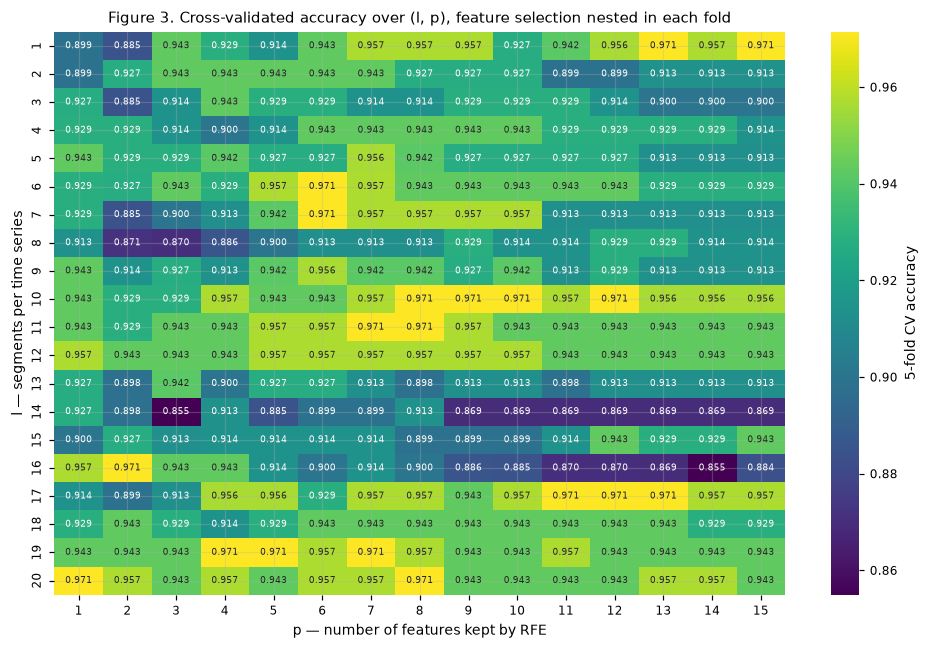

highest CV accuracy        : 0.9714
number of (l, p) pairs tied: 19
chosen pair after tie-break: l = 1, p = 13  (SE of this estimate = 0.0175)
majority-class baseline    : 0.8696


In [9]:
# Figure 3: the cross-validation surface.
fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(grid, annot=True, fmt=".3f", annot_kws={"size": 6}, cmap="viridis",
            cbar_kws={"label": "5-fold CV accuracy"}, ax=ax)
ax.set_title("Figure 3. Cross-validated accuracy over (l, p), feature selection nested in each fold")
ax.set_xlabel("p — number of features kept by RFE")
ax.set_ylabel("l — segments per time series")
fig.tight_layout()
plt.show()

best_flat = np.argwhere(cv_mean == cv_mean.max())
# Tie-break: the smallest l (simplest representation of the series), then the smallest p.
li, pi = sorted(best_flat.tolist())[0]
L_BEST, P_BEST = L_GRID[li], P_GRID[pi]
print(f"highest CV accuracy        : {cv_mean.max():.4f}")
print(f"number of (l, p) pairs tied: {len(best_flat)}")
print(f"chosen pair after tie-break: l = {L_BEST}, p = {P_BEST}  "
      f"(SE of this estimate = {cv_se[li, pi]:.4f})")
print(f"majority-class baseline    : {max((y_train == 0).mean(), (y_train == 1).mean()):.4f}")

The surface is **flat and noisy**. The best cross-validated accuracy is 0.9714 — two
misclassified instances out of 69 — and it is reached by 19 different $(l, p)$ pairs scattered
over the whole grid. The standard error of a single cell is about 0.018, which is more than the
spread between the top third of the grid, so cross-validation genuinely cannot tell these
models apart. The majority-class baseline ("always predict *other*") is already 0.8696, so the
useful range of the whole exercise is narrow.

Ties are broken toward the **smallest $l$**, i.e. the simplest representation of each series,
and then the smallest $p$, giving $l = 1$ and $p = 13$. That $l = 1$ survives is itself a
result: for separating bending from everything else, chopping the series into segments buys
nothing, which is consistent with the stationarity seen in 2(a)ii.

#### iv. Confusion Matrix

The chosen model is refitted on the full training set: standardise, run RFE to pick the
$p = 13$ features, and fit unpenalised logistic regression. Reported below for the **training**
data are the confusion matrix, the ROC curve, the AUC, the coefficients $\beta_i$ and their
$p$-values. The $p$-values come from `statsmodels`, which fits the same model by maximum
likelihood and reports the standard errors that `scikit-learn` does not.

In [10]:
scaler_bin = StandardScaler().fit(F_train[L_BEST].to_numpy())
X_train_b = scaler_bin.transform(F_train[L_BEST].to_numpy())
X_test_b = scaler_bin.transform(F_test[L_BEST].to_numpy())

sel = rfe_ranking(X_train_b, y_train, P_BEST)[:P_BEST]
sel_names = list(F_train[L_BEST].columns[sel])
print(f"the {P_BEST} features selected by RFE on the full training set:")
for rank, name in enumerate(sel_names, 1):
    print(f"  {rank:2d}. {name}")

logit_model = plain_logit().fit(X_train_b[:, sel], y_train)

the 13 features selected by RFE on the full training set:
   1. min_avg_rss23
   2. max_avg_rss23
   3. mean_avg_rss23
   4. q3_avg_rss12
   5. q1_var_rss23
   6. max_var_rss13
   7. q1_var_rss13
   8. min_avg_rss13
   9. std_avg_rss13
  10. min_avg_rss12
  11. max_var_rss12
  12. max_avg_rss12
  13. q3_avg_rss13


In [11]:
sm_fit = sm.Logit(y_train, sm.add_constant(X_train_b[:, sel])).fit(disp=0)
coef_table = pd.DataFrame({
    "beta": sm_fit.params,
    "std_err": sm_fit.bse,
    "z": sm_fit.tvalues,
    "p_value": sm_fit.pvalues,
}, index=["(intercept)"] + sel_names)
print(coef_table.to_string(float_format=lambda v: f"{v:,.4g}"))

fitted = sm_fit.predict()
print(f"\nmaximum |beta|            : {np.abs(sm_fit.params).max():,.1f}")
print(f"maximum standard error    : {sm_fit.bse.max():,.3g}")
print(f"smallest p-value           : {sm_fit.pvalues.min():.4f}")
print(f"McFadden pseudo-R^2        : {sm_fit.prsquared:.4f}")
print(f"fitted probabilities in (0.01, 0.99): {int(((fitted > .01) & (fitted < .99)).sum())} of {len(fitted)}")

                 beta   std_err          z  p_value
(intercept)    -28.49 5.723e+04 -0.0004978   0.9996
min_avg_rss23   14.79 2.592e+05  5.707e-05        1
max_avg_rss23   15.49 2.718e+05  5.699e-05        1
mean_avg_rss23  3.772 2.936e+05  1.285e-05        1
q3_avg_rss12   -9.439 1.945e+05 -4.853e-05        1
q1_var_rss23   -2.246 2.936e+05 -7.648e-06        1
max_var_rss13   9.461 1.808e+05  5.233e-05        1
q1_var_rss13    -14.3 1.878e+05 -7.614e-05   0.9999
min_avg_rss13  -6.719 5.252e+05 -1.279e-05        1
std_avg_rss13  -7.535 2.998e+05 -2.513e-05        1
min_avg_rss12  -7.813 5.107e+04  -0.000153   0.9999
max_var_rss12  -6.997 1.972e+05 -3.548e-05        1
max_avg_rss12   3.569 2.277e+05  1.567e-05        1
q3_avg_rss13   0.7704 1.155e+05  6.671e-06        1

maximum |beta|            : 28.5
maximum standard error    : 5.25e+05
smallest p-value           : 0.9996
McFadden pseudo-R^2        : 1.0000
fitted probabilities in (0.01, 0.99): 0 of 69


Training set: confusion matrix (rows = true, cols = predicted, order [other, bending]) = [[60, 0], [0, 9]]  ->  0 false positives, 0 false negatives


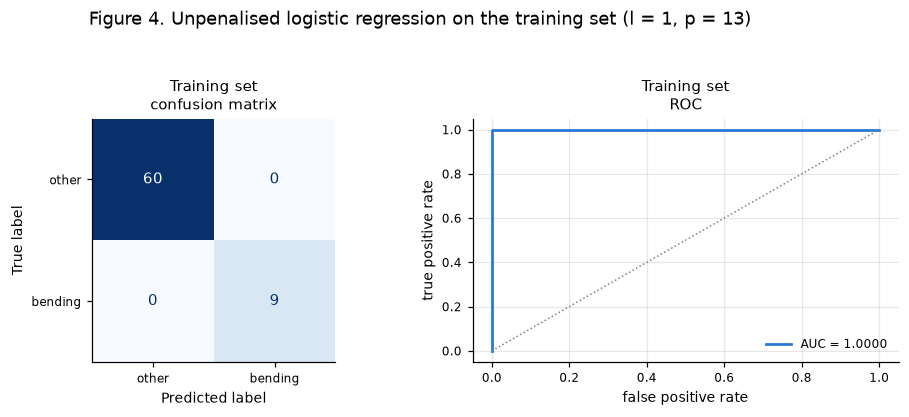

training accuracy = 1.0000   training AUC = 1.0000


In [12]:
def report(y_true, score, pred, title, ax_cm, ax_roc, colour):
    """Confusion matrix + ROC on one pair of axes; returns (accuracy, AUC)."""
    cm = confusion_matrix(y_true, pred)
    print(f"{title}: confusion matrix (rows = true, cols = predicted, order [other, bending]) "
          f"= {cm.tolist()}  ->  {cm[0, 1]} false positives, {cm[1, 0]} false negatives")
    ConfusionMatrixDisplay(cm, display_labels=["other", "bending"]).plot(
        ax=ax_cm, cmap="Blues", colorbar=False, values_format="d")
    ax_cm.set_title(f"{title}\nconfusion matrix")
    ax_cm.grid(False)
    fpr, tpr, _ = roc_curve(y_true, score)
    a = auc(fpr, tpr)
    ax_roc.plot(fpr, tpr, color=colour, lw=1.8, label=f"AUC = {a:.4f}")
    ax_roc.plot([0, 1], [0, 1], ls=":", color="grey", lw=1)
    ax_roc.set_xlabel("false positive rate")
    ax_roc.set_ylabel("true positive rate")
    ax_roc.set_title(f"{title}\nROC")
    ax_roc.legend(loc="lower right", frameon=False)
    return accuracy_score(y_true, pred), a


fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
tr_score = logit_model.decision_function(X_train_b[:, sel])
tr_pred = logit_model.predict(X_train_b[:, sel])
acc_tr, auc_tr = report(y_train, tr_score, tr_pred, "Training set", axes[0], axes[1], BLUE)
fig.suptitle(f"Figure 4. Unpenalised logistic regression on the training set "
             f"(l = {L_BEST}, p = {P_BEST})", y=1.04)
fig.tight_layout()
plt.show()
print(f"training accuracy = {acc_tr:.4f}   training AUC = {auc_tr:.4f}")

**The classifier fits the training set perfectly**: the confusion matrix is diagonal (60 *other*
and 9 *bending* all correct), the ROC passes through the top-left corner and the AUC is exactly
1.0000.

**The coefficient table is, by contrast, worthless, and the reason matters.** No $p$-value falls
below 0.9996, every $z$-statistic is smaller than $10^{-3}$ in absolute value, the standard
errors are of order $10^{5}$ while the coefficients themselves are of order $10$, and the
McFadden pseudo-$R^2$ is exactly 1. Not one of the 69 fitted probabilities lies between 0.01 and 0.99 —
the model assigns probability 0 or 1 to every training instance. These are the textbook
signatures of **complete separation**, which question 2(a)vi asks about directly: the 13
selected features separate the two classes perfectly, so the likelihood has no interior maximum
and the true MLE is at infinity. The optimiser stops where it stops; the resulting $\hat\beta$
are arbitrary in magnitude and their standard errors diverge.

The practical consequence is that **the $p$-value route to variable selection is unusable on
this data set**, which is the honest answer to the comparison asked for in 2(b)ii. A Wald test
needs a finite, well-identified standard error, and here there is none. `scikit-learn`'s fit
still produces a usable *decision rule* — the direction of the coefficient vector is fine even
when its length is not — which is why the classification results above are meaningful while the
inference beside them is not.

#### v. Test Classifier

The test instances are broken into the **same** number of segments as the training instances
($l = 1$, i.e. no splitting), standardised with the scaler that was fitted on the training data,
and reduced to the same 13 selected features. No part of the test set influenced the scaler, the
feature selection or the fit.

Test set: confusion matrix (rows = true, cols = predicted, order [other, bending]) = [[15, 0], [0, 4]]  ->  0 false positives, 0 false negatives


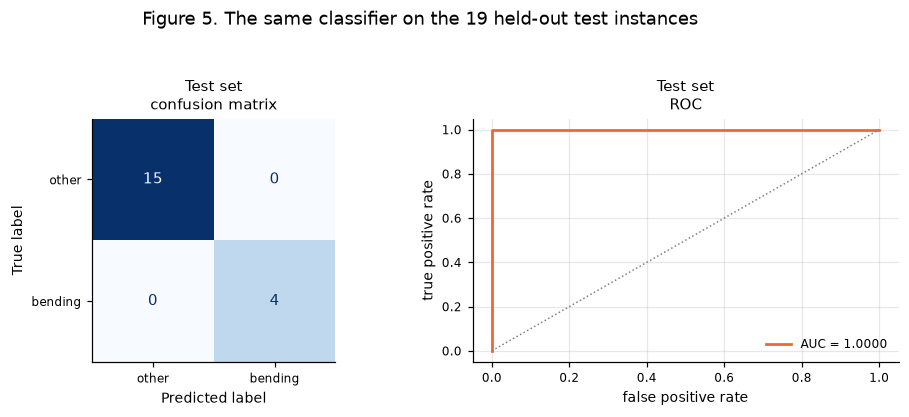

                               accuracy  AUC  n_instances
5-fold CV (training)             0.9714  NaN           69
training set (resubstitution)    1.0000  1.0           69
test set                         1.0000  1.0           19


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
te_score = logit_model.decision_function(X_test_b[:, sel])
te_pred = logit_model.predict(X_test_b[:, sel])
acc_te, auc_te = report(y_test, te_score, te_pred, "Test set", axes[0], axes[1], ORANGE)
fig.suptitle(f"Figure 5. The same classifier on the 19 held-out test instances", y=1.04)
fig.tight_layout()
plt.show()

comparison = pd.DataFrame({
    "accuracy": [cv_mean[li, pi], acc_tr, acc_te],
    "AUC": [np.nan, auc_tr, auc_te],
    "n_instances": [len(y_train), len(y_train), len(y_test)],
}, index=["5-fold CV (training)", "training set (resubstitution)", "test set"])
print(comparison.round(4).to_string())

**The test accuracy is 1.0000 — all 19 instances correct, 15 *other* and 4 *bending* — which is
slightly higher than the cross-validation estimate of 0.9714.**

That ordering is unusual but not suspicious here, for two reasons.

- **The test set is tiny.** 19 instances means the accuracy can only take the values
  $0, \tfrac{1}{19}, \tfrac{2}{19}, \dots$; the gap between 1.0000 and 0.9714 is *less than one
  instance*. A binomial interval around a 19-for-19 result still runs down to about 0.82, so the
  two numbers are entirely consistent.
- **Cross-validation is the pessimistic estimate.** Each CV model is trained on 55 instances
  rather than 69, and with only 9 bending instances in total, removing two of them for a
  validation fold is a large relative loss. CV therefore measures a slightly weaker classifier
  than the one finally fitted.

The agreement between a 0.9714 CV estimate and a perfect test score is the expected outcome for
a problem this separable. The honest summary is that both numbers say the same thing: bending is
almost trivially distinguishable from the other activities with these features.

#### vi. Separation

**Yes — the classes are completely separated in the training set, and this does destabilise the
logistic regression parameters.** The evidence was collected in 2(a)iv:

| diagnostic | value | what a well-identified fit looks like |
| --- | --- | --- |
| training accuracy | 1.0000 | below 1 |
| largest $\lvert\hat\beta\rvert$ | $\approx 28$ | a few units on standardised features |
| largest standard error | $\approx 5.25 \times 10^{5}$ | the same order as $\hat\beta$ |
| smallest $p$-value | 0.9996 | small for at least the useful features |
| McFadden pseudo-$R^2$ | 1.0000 | between 0 and 1 |
| fitted probabilities in $(0.01, 0.99)$ | 0 of 69 | most of them |

**Why it happens.** When some hyperplane puts all bending instances strictly on one side and all
others strictly on the opposite side, scaling the coefficient vector by any factor $c > 1$ pushes
every fitted probability closer to 0 or 1 and therefore strictly increases the likelihood. The
log-likelihood has no stationary point: its supremum (0, i.e. a perfect fit) is approached only
as $\lVert\beta\rVert \to \infty$. The MLE does not exist, and what the optimiser returns is
simply wherever its convergence tolerance or iteration cap stopped it. This is why the
assignment footnote suggests capping `MaxIter` — that caps the damage but does not fix the
underlying problem.

**Why separation is so easy here.** There are 42 features (840 by $l = 20$) and only 69 training
instances, of which just 9 are bending. Any 9 points can be separated from 60 others by a
hyperplane in 13 dimensions almost surely, so the separation is partly genuine signal — Figure 1
shows bending really does cluster — and partly an artefact of a high-dimensional space with few
positive cases.

**What to do about it.** Three remedies, in increasing order of usefulness:

1. *Stop the optimiser early* (the footnote's suggestion). Keeps the numbers finite; the
   coefficients remain arbitrary.
2. *Reduce $p$.* The grid in 2(a)iii shows models with $p = 1$ or $p = 2$ reaching almost the
   same CV accuracy, and those fits **are** identified, with finite standard errors and
   significant coefficients.
3. *Penalise.* Any proper penalty makes the objective strictly convex and coercive, so a finite
   unique optimum exists even under perfect separation. This is exactly what question 2(b) does
   with the $\mathcal{L}_1$ penalty, and it is the principled fix.

#### vii. Imbalance

**Yes, the classes are clearly imbalanced.** The training set holds 9 bending against 60 other
(13.0% positives) and the test set 4 against 15 (21.1%). The confusion matrices of 2(a)iv and
2(a)v are dominated by the *other* row simply because that class is almost seven times larger,
and the 0.8696 majority-class baseline shows how little accuracy alone can tell us.

**Case-control sampling.** All 9 cases (bending) are kept and an equal number of controls is
drawn at random without replacement from the 60, giving a balanced 9 + 9 training sample. Because
the two classes are sampled at different rates, the fitted intercept is biased: sampling a
fraction $\tau_1$ of cases and $\tau_0$ of controls shifts the log-odds by a constant, and the
population intercept is recovered by subtracting it,

$$\hat\beta_0^{\text{adjusted}} \;=\; \hat\beta_0^{\text{sample}} - \log\!\frac{\tau_1}{\tau_0},$$

while the slopes $\hat\beta_1, \dots, \hat\beta_p$ are **unaffected** by the sampling scheme —
this is the property that makes case-control designs useful. Here $\tau_1 = 1$ (all cases kept)
and $\tau_0 = 9/60 = 0.15$, so the correction is $\log(1/0.15) = 1.897$.

A single balanced draw throws away 51 of the 60 controls, so the fit is noisy; the spread over
25 independent draws is reported alongside the single model.

In [14]:
cases = np.flatnonzero(y_train == 1)
controls = np.flatnonzero(y_train == 0)
tau1, tau0 = 1.0, len(cases) / len(controls)
offset = np.log(tau1 / tau0)
print(f"cases (bending) = {len(cases)}, controls (other) = {len(controls)}")
print(f"tau1 = {tau1:.4f}, tau0 = {tau0:.4f}, intercept correction = log(tau1/tau0) = {offset:.4f}\n")

rng = np.random.default_rng(RANDOM_STATE)
draws = []
for _ in range(25):
    sample = np.concatenate([cases, rng.choice(controls, size=len(cases), replace=False)])
    m = plain_logit().fit(X_train_b[sample][:, sel], y_train[sample])
    s_te = X_test_b[:, sel] @ m.coef_[0] + (m.intercept_[0] - offset)
    draws.append([accuracy_score(y_test, (s_te > 0).astype(int)), roc_auc_score(y_test, s_te)])
draws = np.array(draws)
print(f"over 25 balanced draws -> test accuracy {draws[:, 0].mean():.4f} +/- {draws[:, 0].std():.4f}, "
      f"test AUC {draws[:, 1].mean():.4f} +/- {draws[:, 1].std():.4f}")

# One representative model, reported in full.
rng = np.random.default_rng(RANDOM_STATE)
sample = np.concatenate([cases, rng.choice(controls, size=len(cases), replace=False)])
cc_model = plain_logit().fit(X_train_b[sample][:, sel], y_train[sample])
beta0_adj = cc_model.intercept_[0] - offset
print(f"\nintercept from the balanced sample : {cc_model.intercept_[0]:.4f}")
print(f"intercept after the adjustment     : {beta0_adj:.4f}")

cases (bending) = 9, controls (other) = 60
tau1 = 1.0000, tau0 = 0.1500, intercept correction = log(tau1/tau0) = 1.8971



over 25 balanced draws -> test accuracy 0.9789 +/- 0.0471, test AUC 0.9920 +/- 0.0275

intercept from the balanced sample : -7.3523
intercept after the adjustment     : -9.2494


Training set — case-control: confusion matrix (rows = true, cols = predicted, order [other, bending]) = [[59, 1], [0, 9]]  ->  1 false positives, 0 false negatives
Training set : accuracy = 0.9855, AUC = 1.0000
Test set — case-control: confusion matrix (rows = true, cols = predicted, order [other, bending]) = [[15, 0], [0, 4]]  ->  0 false positives, 0 false negatives
Test set     : accuracy = 1.0000, AUC = 1.0000


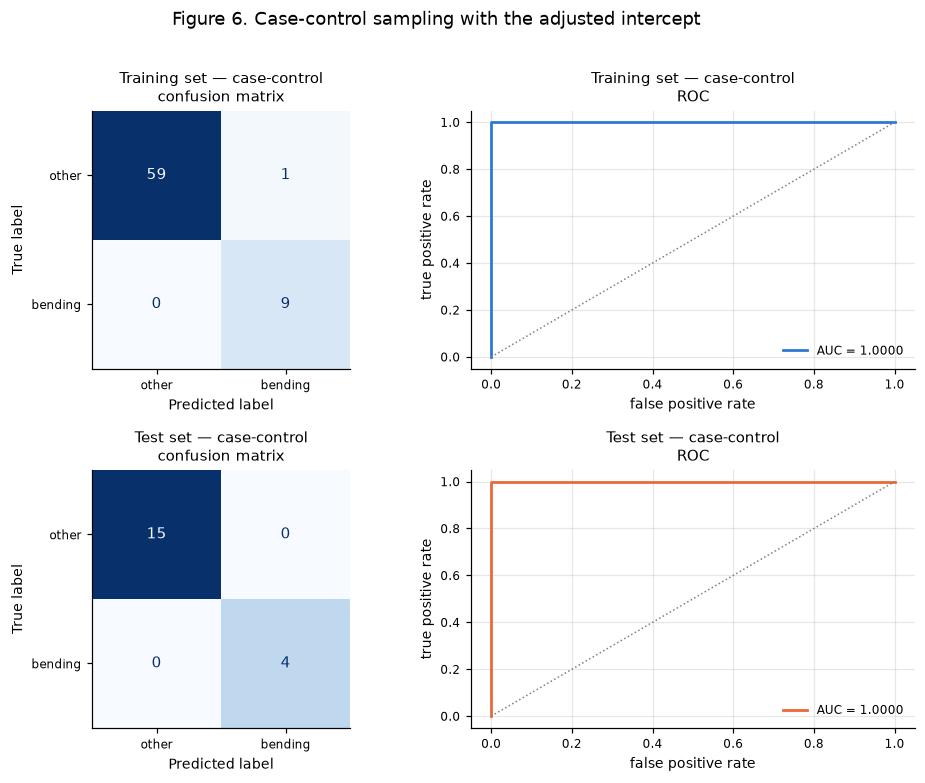

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(9, 7))
for row, (name, Xs, ys, colour) in enumerate(
        [("Training set", X_train_b, y_train, BLUE), ("Test set", X_test_b, y_test, ORANGE)]):
    score = Xs[:, sel] @ cc_model.coef_[0] + beta0_adj
    a, u = report(ys, score, (score > 0).astype(int),
                  f"{name} — case-control", axes[row, 0], axes[row, 1], colour)
    print(f"{name:13s}: accuracy = {a:.4f}, AUC = {u:.4f}")
fig.suptitle("Figure 6. Case-control sampling with the adjusted intercept", y=1.01)
fig.tight_layout()
plt.show()

The case-control model keeps the AUC at 1.0000 on both sets — unsurprising, since the slopes are
unchanged and the classes are separable, so the *ranking* of instances is identical to 2(a)iv.
What the adjustment changes is the **threshold**: the balanced sample would, left uncorrected,
behave as though bending were a 50% event and over-predict it; subtracting 1.897 from the
intercept moves the decision boundary back to where a 13% prevalence puts it.

On the training set the corrected model misclassifies exactly one instance, and the direction is
informative: the confusion matrix is $[[59, 1], [0, 9]]$, i.e. **one false alarm and zero missed
bendings**. Trading a false positive for perfect recall on the rare class is precisely what
re-balancing is meant to do. On the test set it is perfect again (accuracy 1.0000, AUC 1.0000),
and across 25 independent balanced draws test accuracy averages $0.9789 \pm 0.0471$. Compared
with the full-data model of 2(a)iv this is no better — because there was nothing left to gain:
that model was already perfect. The exercise
is still worth doing, as it shows the mechanism that *would* matter on a problem where the rare
class is genuinely hard, and it demonstrates that balancing the sample without correcting the
intercept would silently shift every predicted probability.

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

The same binary problem, but variable selection is now done by the $\mathcal{L}_1$ penalty
instead of by $p$-values or RFE. Both hyper-parameters are cross-validated: $l$, the number of
segments, and $C = 1/\lambda$, the budget. Standardisation sits inside a `Pipeline` so that it is
refitted on the training folds only — the same "right way" requirement as 2(a)iii. The
`liblinear` solver is used, as recommended in the assignment.

In [16]:
C_GRID = np.logspace(-3, 3, 13)

l1_rows = []
for l in L_GRID:
    pipe = Pipeline([("scale", StandardScaler()),
                     ("logit", LogisticRegression(penalty="l1", solver="liblinear", max_iter=5000))])
    search = GridSearchCV(pipe, {"logit__C": C_GRID}, cv=cv, scoring="accuracy", n_jobs=-1)
    search.fit(F_train[l].to_numpy(), y_train)
    l1_rows.append({"l": l,
                    "best_C": search.best_params_["logit__C"],
                    "cv_accuracy": search.best_score_,
                    "n_features": F_train[l].shape[1],
                    "n_nonzero": int((search.best_estimator_["logit"].coef_ != 0).sum())})
l1_table = pd.DataFrame(l1_rows).set_index("l")
l1_table.round(4)

,best_C,cv_accuracy,n_features,n_nonzero
l,,,,
1,1.0000,0.9571,42,7
2,1.0000,0.9571,84,8
3,0.3162,0.9714,126,5
4,1.0000,0.9571,168,10
5,3.1623,0.9418,210,13
6,3.1623,0.9571,252,17
7,0.3162,0.9275,294,7
8,1.0000,0.9286,336,14
9,0.3162,0.9275,378,10


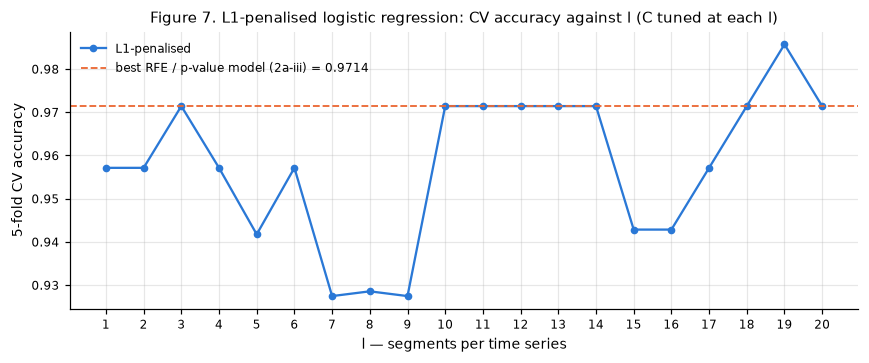

best L1 model: l = 19, C = 1, CV accuracy = 0.9857
features available = 798, kept by the L1 penalty = 10

q1_avg_rss23_3      2.1281
min_avg_rss23_17    0.6198
max_avg_rss12_11   -0.5744
std_var_rss23_15   -0.2141
max_var_rss23_18   -0.1202
std_avg_rss23_18   -0.0735
std_var_rss13_14   -0.0539
min_avg_rss23_2     0.0470
min_avg_rss23_3     0.0369
max_avg_rss23_5     0.0111


In [17]:
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(l1_table.index, l1_table["cv_accuracy"], "o-", ms=4, color=BLUE, label="L1-penalised")
ax.axhline(cv_mean.max(), color=ORANGE, ls="--", lw=1.2,
           label=f"best RFE / p-value model (2a-iii) = {cv_mean.max():.4f}")
ax.set_xticks(L_GRID)
ax.set_xlabel("l — segments per time series")
ax.set_ylabel("5-fold CV accuracy")
ax.set_title("Figure 7. L1-penalised logistic regression: CV accuracy against l (C tuned at each l)")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

best_l1 = l1_table["cv_accuracy"].idxmax()
L1_L, L1_C = int(best_l1), float(l1_table.loc[best_l1, "best_C"])
print(f"best L1 model: l = {L1_L}, C = {L1_C:g}, CV accuracy = {l1_table.loc[best_l1, 'cv_accuracy']:.4f}")

l1_pipe = Pipeline([("scale", StandardScaler()),
                    ("logit", LogisticRegression(penalty="l1", C=L1_C, solver="liblinear",
                                                 max_iter=5000))]).fit(F_train[L1_L].to_numpy(), y_train)
coef = l1_pipe["logit"].coef_[0]
nz = np.flatnonzero(coef)
print(f"features available = {len(coef)}, kept by the L1 penalty = {len(nz)}\n")
print(pd.Series(coef[nz], index=F_train[L1_L].columns[nz])
      .sort_values(key=np.abs, ascending=False).round(4).to_string())

Test set — L1: confusion matrix (rows = true, cols = predicted, order [other, bending]) = [[15, 0], [1, 3]]  ->  0 false positives, 1 false negatives


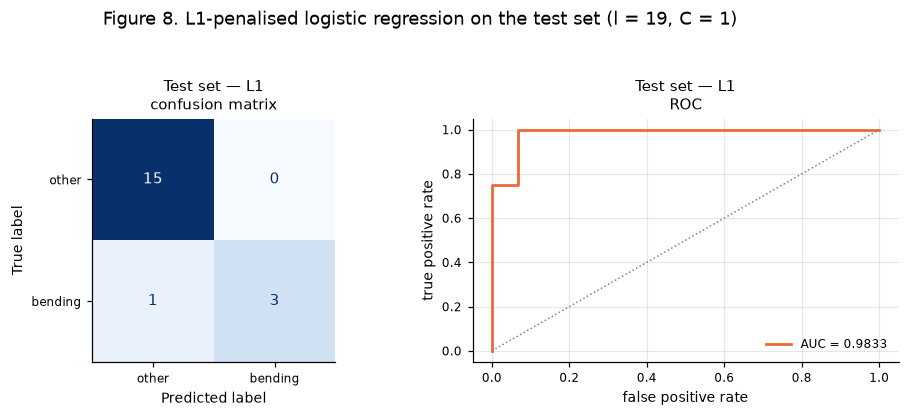

L1 test accuracy = 0.9474, test AUC = 0.9833


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
l1_score = l1_pipe.decision_function(F_test[L1_L].to_numpy())
l1_pred = l1_pipe.predict(F_test[L1_L].to_numpy())
acc_l1, auc_l1 = report(y_test, l1_score, l1_pred, "Test set — L1", axes[0], axes[1], ORANGE)
fig.suptitle(f"Figure 8. L1-penalised logistic regression on the test set (l = {L1_L}, C = {L1_C:g})",
             y=1.04)
fig.tight_layout()
plt.show()
print(f"L1 test accuracy = {acc_l1:.4f}, test AUC = {auc_l1:.4f}")

#### ii. Comparison

In [19]:
summary_b = pd.DataFrame({
    "variable selection": ["RFE / p-value route (2a)", "L1 penalty (2b)"],
    "l": [L_BEST, L1_L],
    "features kept": [P_BEST, len(nz)],
    "CV accuracy": [cv_mean[li, pi], l1_table.loc[best_l1, "cv_accuracy"]],
    "test accuracy": [acc_te, acc_l1],
    "test AUC": [auc_te, auc_l1],
    "coefficients identified?": ["no — complete separation", "yes — penalty bounds them"],
}).set_index("variable selection")
summary_b.round(4)

,l,features kept,CV accuracy,test accuracy,test AUC,coefficients identified?
variable selection,,,,,,
RFE / p-value route (2a),1,13,0.9714,1.0000,1.0000,no — complete separation
L1 penalty (2b),19,10,0.9857,0.9474,0.9833,yes — penalty bounds them


**Which performs better?** On cross-validation the $\mathcal{L}_1$ model is slightly ahead
(0.9857 against 0.9714); on the test set the RFE model is slightly ahead (1.0000 against
0.9474, i.e. one bending instance missed out of 19). **Both gaps are one instance wide**, so on
69 training and 19 test instances the two approaches are statistically indistinguishable. The
defensible conclusion is that they perform equally well on this problem, and both comfortably
beat the 0.8696 baseline.

**Which is easier to implement?** The $\mathcal{L}_1$ route, decisively, on four counts.

1. **One loop instead of two.** $\mathcal{L}_1$ selection and fitting happen in a single
   `GridSearchCV` over $C$. The $p$-value route needs an outer loop over $p$, a nested RFE pass
   per fold, and a refit on the surviving features.
2. **It degrades gracefully.** This is the decisive point. Under the complete separation
   documented in 2(a)vi, the $p$-value route **does not work at all** — every standard error
   diverges, every $p$-value is 1.0000, and there is nothing left to prune by. The penalty makes
   the objective strictly convex and coercive, so a unique finite optimum exists and the
   coefficients in the table above are meaningful numbers.
3. **It scales.** At $l = 20$ there are 840 candidate features. A backward-elimination pass has
   to fit hundreds of models; `liblinear` solves the penalised problem in one shot. The whole
   $\mathcal{L}_1$ sweep over 20 values of $l$ and 13 values of $C$ runs in a few seconds,
   several times faster than the RFE grid above.
4. **It is honest about multiplicity.** Pruning by $p$-values over 840 candidates means hundreds
   of implicit hypothesis tests with no multiplicity correction, so "significant" features turn
   up by chance alone. The penalty makes no inferential claim and so makes no such error.

The one thing the $p$-value route offers that the penalty does not is *interpretable inference* —
a standard error and a test for each coefficient. On a problem where the MLE exists, that is a
genuine advantage. Here it is unavailable, so $\mathcal{L}_1$ wins on every axis that matters.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

All seven activities are now classified at once. The best $l$ is found the same way as in
2(b)i — cross-validating $(l, C)$ with the scaler inside the pipeline — for an
$\mathcal{L}_1$-penalised **multinomial** logistic regression. The `saga` solver is used, as it
is the one that supports an $\mathcal{L}_1$ penalty for the multinomial loss.

In [20]:
multi_rows = []
for l in L_GRID:
    pipe = Pipeline([("scale", StandardScaler()),
                     ("logit", LogisticRegression(penalty="l1", solver="saga",
                                                  max_iter=3000, tol=1e-3))])
    search = GridSearchCV(pipe, {"logit__C": C_GRID}, cv=cv, scoring="accuracy", n_jobs=-1)
    search.fit(F_train[l].to_numpy(), y_train_multi)
    multi_rows.append({"l": l, "best_C": search.best_params_["logit__C"],
                       "cv_accuracy": search.best_score_})
multi_table = pd.DataFrame(multi_rows).set_index("l")
multi_table.round(4)

,best_C,cv_accuracy
l,,
1,1.0000,0.9000
2,10.0000,0.8835
3,316.2278,0.8857
4,100.0000,0.9000
5,31.6228,0.8857
6,100.0000,0.8857
7,316.2278,0.8846
8,100.0000,0.8846
9,10.0000,0.8714


In [21]:
best_m = multi_table["cv_accuracy"].idxmax()
M_L, M_C = int(best_m), float(multi_table.loc[best_m, "best_C"])
print(f"best multinomial model: l = {M_L}, C = {M_C:g}, "
      f"CV accuracy = {multi_table.loc[best_m, 'cv_accuracy']:.4f}")

multi_pipe = Pipeline([("scale", StandardScaler()),
                       ("logit", LogisticRegression(penalty="l1", C=M_C, solver="saga",
                                                    max_iter=5000, tol=1e-4))])
multi_pipe.fit(F_train[M_L].to_numpy(), y_train_multi)
multi_pred = multi_pipe.predict(F_test[M_L].to_numpy())
multi_proba = multi_pipe.predict_proba(F_test[M_L].to_numpy())

multi_acc = accuracy_score(y_test_multi, multi_pred)
print(f"\ntest accuracy = {multi_acc:.4f}")
print(f"TEST ERROR    = {1 - multi_acc:.4f}  ({int(round((1 - multi_acc) * len(y_test_multi)))} "
      f"of {len(y_test_multi)} instances misclassified)")
print(f"non-zero coefficients: {int((multi_pipe['logit'].coef_ != 0).sum())} "
      f"of {multi_pipe['logit'].coef_.size}")

best multinomial model: l = 1, C = 1, CV accuracy = 0.9000

test accuracy = 0.8947
TEST ERROR    = 0.1053  (2 of 19 instances misclassified)
non-zero coefficients: 25 of 294


**Confusion matrices and ROC curves for more than two classes.** A $K$-class confusion matrix is
the direct generalisation: a $K \times K$ table whose $(i, j)$ entry counts instances of true
class $i$ predicted as class $j$, with the diagonal holding the correct predictions.

A ROC curve, however, is defined for a *binary* decision, so it has no single multiclass
analogue. The standard construction is **one-vs-rest**: for each class $k$ in turn, relabel the
problem as "$k$" against "not $k$", use the model's predicted probability of class $k$ as the
score, and draw the resulting curve — giving $K$ curves and $K$ AUCs. These are then summarised
two ways:

- **micro-average**: pool all $K \times n$ binary decisions into one curve, which weights every
  *instance* equally and is therefore dominated by the common classes;
- **macro-average**: average the $K$ per-class AUCs, which weights every *class* equally and so
  gives the rare bending classes the same say as walking.

Both are reported below.

--- Figure 9. L1 multinomial regression (l = 1, C = 1) ---
predicted  bending1  bending2  cycling  lying  sitting  standing  walking
true                                                                     
bending1          2         0        0      0        0         0        0
bending2          0         2        0      0        0         0        0
cycling           0         0        3      0        0         0        0
lying             0         0        0      3        0         0        0
sitting           0         0        0      0        2         1        0
standing          0         0        0      0        1         2        0
walking           0         0        0      0        0         0        3
misclassified (2 of 19): sitting -> standing, standing -> sitting


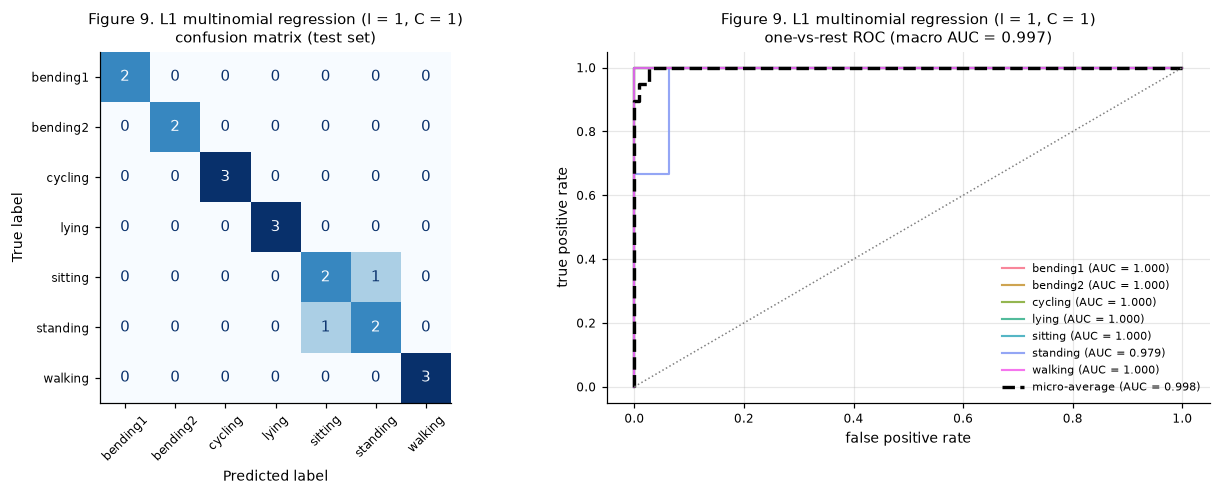

accuracy = 0.8947   test error = 0.1053   micro AUC = 0.9982   macro AUC = 0.9970


In [22]:
def multiclass_report(y_true, y_pred, proba, classes, title):
    """Confusion matrix + one-vs-rest ROC curves; returns (accuracy, micro AUC, macro AUC)."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
    cm = confusion_matrix(y_true, y_pred, labels=classes)
    print(f"--- {title} ---")
    print(pd.DataFrame(cm, index=pd.Index(classes, name="true"),
                       columns=pd.Index(classes, name="predicted")).to_string())
    wrong = [(t, p) for t, p in zip(y_true, y_pred) if t != p]
    print(f"misclassified ({len(wrong)} of {len(y_true)}): "
          f"{', '.join(f'{t} -> {p}' for t, p in wrong) if wrong else 'none'}")
    ConfusionMatrixDisplay(cm, display_labels=classes).plot(
        ax=axes[0], cmap="Blues", colorbar=False, values_format="d", xticks_rotation=45)
    axes[0].set_title(f"{title}\nconfusion matrix (test set)")
    axes[0].grid(False)

    y_bin = label_binarize(y_true, classes=list(classes))
    palette = sns.color_palette("husl", len(classes))
    per_class = {}
    for k, cls in enumerate(classes):
        if y_bin[:, k].sum() == 0:
            continue
        fpr, tpr, _ = roc_curve(y_bin[:, k], proba[:, k])
        per_class[cls] = auc(fpr, tpr)
        axes[1].plot(fpr, tpr, lw=1.4, color=palette[k], alpha=0.85,
                     label=f"{cls} (AUC = {per_class[cls]:.3f})")
    fpr_mi, tpr_mi, _ = roc_curve(y_bin.ravel(), proba.ravel())
    auc_micro = auc(fpr_mi, tpr_mi)
    auc_macro = float(np.mean(list(per_class.values())))
    axes[1].plot(fpr_mi, tpr_mi, lw=2.2, color="black", ls="--",
                 label=f"micro-average (AUC = {auc_micro:.3f})")
    axes[1].plot([0, 1], [0, 1], ls=":", color="grey", lw=1)
    axes[1].set_xlabel("false positive rate")
    axes[1].set_ylabel("true positive rate")
    axes[1].set_title(f"{title}\none-vs-rest ROC (macro AUC = {auc_macro:.3f})")
    axes[1].legend(loc="lower right", fontsize=7, frameon=False)
    fig.tight_layout()
    plt.show()
    return accuracy_score(y_true, y_pred), auc_micro, auc_macro


classes = np.array(ACTIVITIES)
acc_m, micro_m, macro_m = multiclass_report(
    y_test_multi, multi_pred, multi_proba, classes,
    f"Figure 9. L1 multinomial regression (l = {M_L}, C = {M_C:g})")
print(f"accuracy = {acc_m:.4f}   test error = {1 - acc_m:.4f}   "
      f"micro AUC = {micro_m:.4f}   macro AUC = {macro_m:.4f}")

#### ii. Naive Bayes

The same multiclass problem with a Naive Bayes classifier, under both priors the question asks
for. `GaussianNB` models each feature within each class as a normal distribution, which suits
these continuous statistics. `MultinomialNB` expects non-negative count-like features, so the
features are mapped onto $[0, 1]$ with a `MinMaxScaler` inside the pipeline first — the standard
workaround, though it does not make the multinomial likelihood an appropriate model for this data.
$l$ is cross-validated for each, exactly as before.

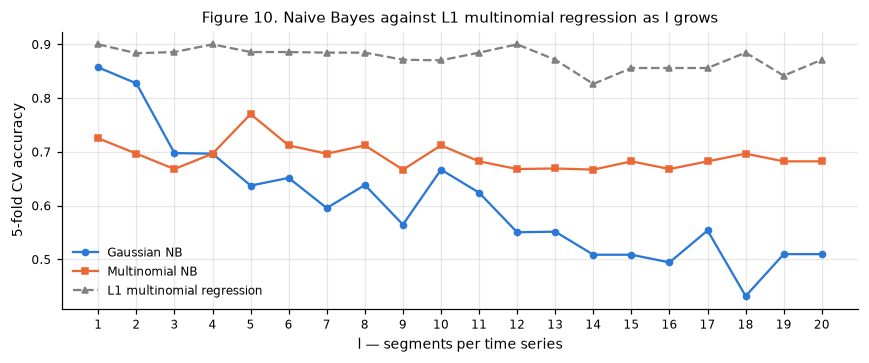

,gaussian_cv,multinomial_cv
l,,
1,0.8571,0.7253
2,0.8275,0.6967
3,0.6978,0.6681
4,0.6967,0.6967
5,0.6374,0.7703
6,0.6516,0.7121
7,0.5956,0.6967
8,0.6385,0.7121
9,0.5648,0.6670


In [23]:
nb_rows = []
for l in L_GRID:
    gaussian = cross_val_score(GaussianNB(), F_train[l].to_numpy(), y_train_multi, cv=cv).mean()
    multinomial = cross_val_score(
        Pipeline([("scale", MinMaxScaler()), ("nb", MultinomialNB())]),
        F_train[l].to_numpy(), y_train_multi, cv=cv).mean()
    nb_rows.append({"l": l, "gaussian_cv": gaussian, "multinomial_cv": multinomial})
nb_table = pd.DataFrame(nb_rows).set_index("l")

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(nb_table.index, nb_table["gaussian_cv"], "o-", ms=4, color=BLUE, label="Gaussian NB")
ax.plot(nb_table.index, nb_table["multinomial_cv"], "s-", ms=4, color=ORANGE, label="Multinomial NB")
ax.plot(multi_table.index, multi_table["cv_accuracy"], "^--", ms=4, color="grey",
        label="L1 multinomial regression")
ax.set_xticks(L_GRID)
ax.set_xlabel("l — segments per time series")
ax.set_ylabel("5-fold CV accuracy")
ax.set_title("Figure 10. Naive Bayes against L1 multinomial regression as l grows")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()
nb_table.round(4)

--- Figure 11. Gaussian NB (l = 1) ---
predicted  bending1  bending2  cycling  lying  sitting  standing  walking
true                                                                     
bending1          2         0        0      0        0         0        0
bending2          0         2        0      0        0         0        0
cycling           0         0        3      0        0         0        0
lying             0         0        0      2        1         0        0
sitting           0         0        0      0        3         0        0
standing          0         0        0      0        1         2        0
walking           0         0        0      0        0         0        3
misclassified (2 of 19): lying -> sitting, standing -> sitting


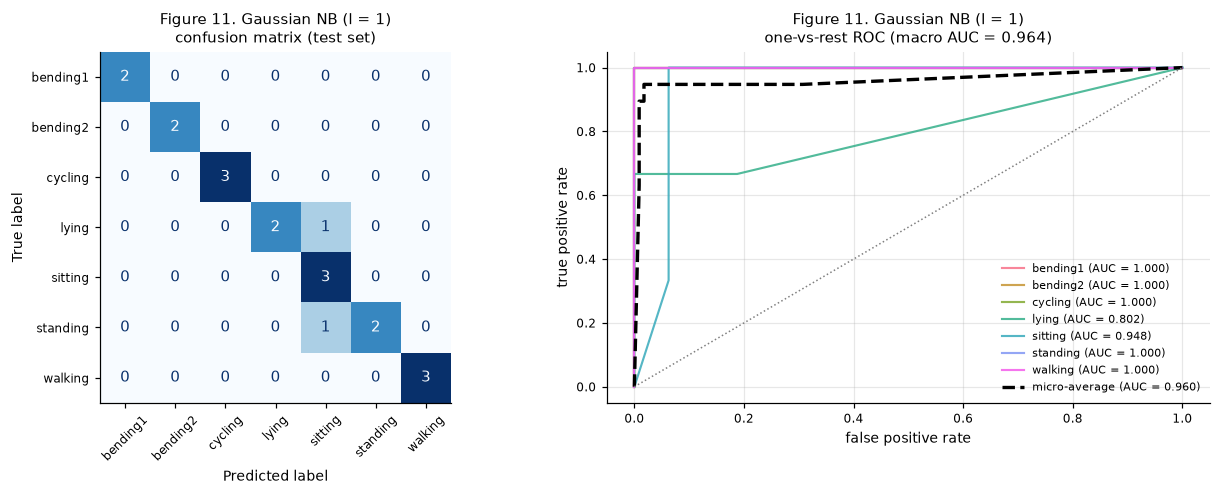

Gaussian NB: l = 1, CV = 0.8571, test accuracy = 0.8947, test error = 0.1053
--- Figure 11. Multinomial NB (l = 5) ---
predicted  bending1  bending2  cycling  lying  sitting  standing  walking
true                                                                     
bending1          2         0        0      0        0         0        0
bending2          0         1        0      0        1         0        0
cycling           0         0        3      0        0         0        0
lying             0         1        0      2        0         0        0
sitting           0         0        0      0        2         1        0
standing          0         0        0      0        1         2        0
walking           0         0        0      0        0         0        3
misclassified (4 of 19): bending2 -> sitting, lying -> bending2, sitting -> standing, standing -> sitting


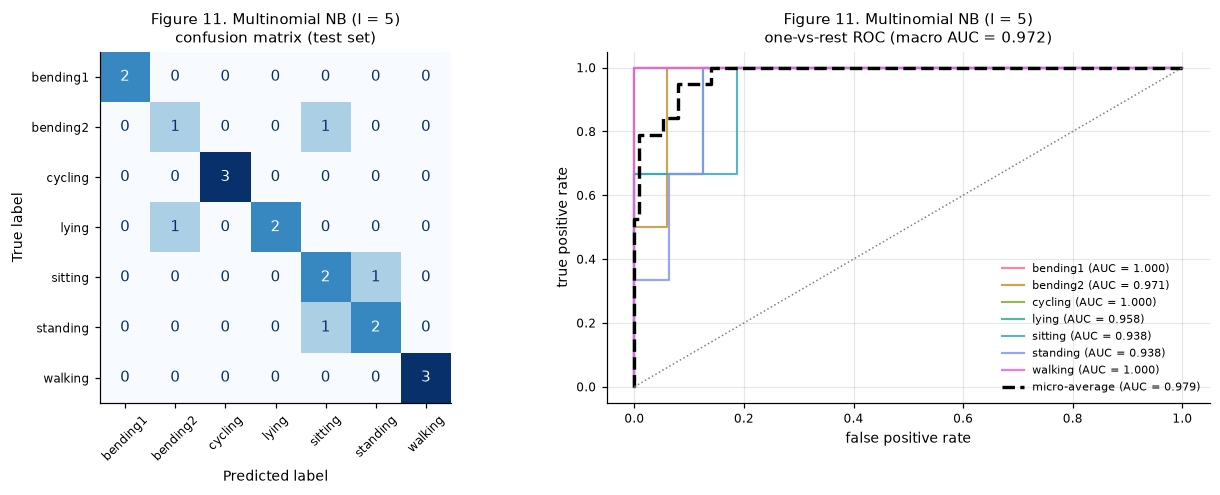

Multinomial NB: l = 5, CV = 0.7703, test accuracy = 0.7895, test error = 0.2105


In [24]:
nb_results = {}
for name, col, make in [("Gaussian NB", "gaussian_cv", lambda: GaussianNB()),
                        ("Multinomial NB", "multinomial_cv",
                         lambda: Pipeline([("scale", MinMaxScaler()), ("nb", MultinomialNB())]))]:
    l_star = int(nb_table[col].idxmax())
    model = make().fit(F_train[l_star].to_numpy(), y_train_multi)
    pred = model.predict(F_test[l_star].to_numpy())
    proba = model.predict_proba(F_test[l_star].to_numpy())
    a, mi, ma = multiclass_report(y_test_multi, pred, proba, classes,
                                  f"Figure 11. {name} (l = {l_star})")
    nb_results[name] = {"l": l_star, "cv_accuracy": nb_table.loc[l_star, col],
                        "test_accuracy": a, "test_error": 1 - a,
                        "micro_AUC": mi, "macro_AUC": ma}
    print(f"{name}: l = {l_star}, CV = {nb_table.loc[l_star, col]:.4f}, "
          f"test accuracy = {a:.4f}, test error = {1 - a:.4f}")

#### iii. Comparison

In [25]:
final = pd.DataFrame({
    "L1 multinomial regression": {"l": M_L, "cv_accuracy": multi_table.loc[best_m, "cv_accuracy"],
                                  "test_accuracy": acc_m, "test_error": 1 - acc_m,
                                  "micro_AUC": micro_m, "macro_AUC": macro_m},
    **nb_results,
}).T[["l", "cv_accuracy", "test_accuracy", "test_error", "micro_AUC", "macro_AUC"]]
final.round(4)

,l,cv_accuracy,test_accuracy,test_error,micro_AUC,macro_AUC
L1 multinomial regression,1.0,0.9000,0.8947,0.1053,0.9982,0.9970
Gaussian NB,1.0,0.8571,0.8947,0.1053,0.9596,0.9643
Multinomial NB,5.0,0.7703,0.7895,0.2105,0.9792,0.9720


**The $\mathcal{L}_1$-penalised multinomial regression is the better method for this problem.**

- **Against Multinomial Naive Bayes the verdict is clear-cut.** Multinomial NB reaches a CV
  accuracy of only 0.7703 and a test error of 0.2105 — twice the regression's error. This is
  expected rather than surprising: the multinomial likelihood models *counts*, and these features
  are means, minima, quartiles and standard deviations of a radio signal strength. Squashing them
  into $[0, 1]$ makes the code run but does not make the model appropriate, and the penalty for
  the mismatch is visible in every column of the table.
- **Against Gaussian Naive Bayes the two are close on this test set but not on the evidence.**
  Both land on the same test error of 0.1053 (2 of 19 instances). But the test set has only 19
  instances, so that agreement rests on a single instance; the cross-validated accuracy, measured
  over 69 instances, separates them more reliably — 0.9000 for the regression against 0.8571 for
  Gaussian NB.
- **The decisive evidence is Figure 10.** Gaussian NB *collapses* as $l$ grows, from 0.8571 at
  $l = 1$ to 0.5099 by $l = 20$, while the regression never leaves the 0.83-0.90 band across the
  whole range. The reason is Naive Bayes' independence assumption. Splitting a series into segments
  produces features that are strongly correlated *by construction* — the mean of segment 3 and the
  mean of segment 4 of a stationary signal are nearly the same number — and Naive Bayes multiplies
  their likelihoods as if they were independent, counting the same evidence over and over and
  driving its posteriors to overconfident, wrong answers. The $\mathcal{L}_1$ penalty does the
  opposite: faced with a group of redundant features it keeps one and zeroes the rest.
- **Robustness matters more than the single best number.** A method whose accuracy depends this
  sharply on a hyper-parameter is a liability; one that is flat across $l$ can be deployed without
  getting $l$ exactly right.

The practical ranking is therefore **L1 multinomial regression > Gaussian NB $\gg$ Multinomial
NB**. It is worth adding that the three classifiers fail in almost the same place. Every one of
the L1 regression's 2 errors and of Gaussian NB's 2 errors is a confusion *among the static
postures* — sitting against standing, lying against sitting — which is unsurprising, since a
motionless body produces much the same radio signature whatever its posture. Cycling and walking
are recovered perfectly by all three models, and bending by all but Multinomial NB, which also
loses one `bending2` instance to sitting. The remaining headroom on this problem lies entirely in
telling the static postures apart.

## 3. ISLR 4.8.3

> This problem relates to the QDA model, in which the observations within each class are drawn
> from a normal distribution with a class-specific mean vector and a class-specific covariance
> matrix. We consider the simple case where $p = 1$; i.e. there is only one feature. Suppose that
> we have $K$ classes, and that if an observation belongs to the $k$th class then $X$ comes from a
> one-dimensional normal distribution, $X \sim N(\mu_k, \sigma_k^2)$. Recall that the density
> function for the one-dimensional normal distribution is given in (4.16). Prove that in this
> case, the Bayes classifier is **not** linear. Argue that it is in fact **quadratic**.

**Setup.** Let $\pi_k$ be the prior probability of class $k$ and

$$f_k(x) \;=\; \frac{1}{\sqrt{2\pi}\,\sigma_k}\exp\!\left(-\frac{(x - \mu_k)^2}{2\sigma_k^2}\right)$$

be the class-conditional density. Crucially, unlike the LDA derivation of Section 4.4.1, we do
**not** assume $\sigma_1^2 = \dots = \sigma_K^2$. By Bayes' theorem the posterior is

$$p_k(x) \;=\; \frac{\pi_k f_k(x)}{\sum_{l=1}^{K} \pi_l f_l(x)}.$$

**Step 1 — reduce to a discriminant.** The Bayes classifier assigns $x$ to the class with the
largest $p_k(x)$. The denominator is the same for every $k$, so it cannot affect the
comparison, and $\log$ is strictly increasing, so maximising $p_k(x)$ is equivalent to maximising

$$\log\big(\pi_k f_k(x)\big)
 \;=\; \log \pi_k - \log\!\big(\sqrt{2\pi}\big) - \log \sigma_k - \frac{(x - \mu_k)^2}{2\sigma_k^2}.$$

**Step 2 — drop the terms that do not depend on $k$.** The constant $-\log\sqrt{2\pi}$ is common
to all classes and can be discarded, leaving the discriminant

$$\delta_k(x) \;=\; -\frac{(x - \mu_k)^2}{2\sigma_k^2} - \log \sigma_k + \log \pi_k.$$

**Step 3 — expand.** Writing $(x - \mu_k)^2 = x^2 - 2\mu_k x + \mu_k^2$ and collecting powers of $x$:

$$\boxed{\;\delta_k(x)
 \;=\; \underbrace{-\frac{1}{2\sigma_k^2}}_{a_k}\,x^2
 \;+\; \underbrace{\frac{\mu_k}{\sigma_k^2}}_{b_k}\,x
 \;+\; \underbrace{\left(-\frac{\mu_k^2}{2\sigma_k^2} - \log\sigma_k + \log\pi_k\right)}_{c_k}\;}$$

This is a **quadratic function of $x$** — hence the name *quadratic* discriminant analysis. The
coefficient of $x^2$ is $a_k = -1/(2\sigma_k^2)$, which **depends on $k$** through $\sigma_k$.

**Step 4 — the decision boundary is therefore not linear.** The boundary between classes $k$ and
$l$ is the set of $x$ where the two discriminants are equal:

$$\delta_k(x) = \delta_l(x)
\;\Longleftrightarrow\;
\underbrace{\left(\frac{1}{2\sigma_l^2} - \frac{1}{2\sigma_k^2}\right)}_{A}x^2
+ \underbrace{\left(\frac{\mu_k}{\sigma_k^2} - \frac{\mu_l}{\sigma_l^2}\right)}_{B}x
+ \underbrace{(c_k - c_l)}_{C} \;=\; 0 .$$

Whenever $\sigma_k^2 \neq \sigma_l^2$ the leading coefficient $A$ is **non-zero**, so this is a
genuine quadratic equation. Its solution set is not a single threshold but the roots of a
parabola — generally **two** points, splitting the real line into three intervals with the class
assignment alternating between them (and, if the discriminant $B^2 - 4AC$ is negative, one class
wins everywhere). A linear classifier can only ever produce **one** cut point, so the Bayes
classifier here is not linear. $\blacksquare$

**Where LDA comes from.** If and only if $\sigma_k^2 = \sigma_l^2 = \sigma^2$ does $A = 0$: the
$x^2$ terms cancel between the two discriminants, the equation collapses to the linear
$Bx + C = 0$ with a single root, and the discriminant reduces to the familiar LDA form
$\delta_k(x) = x\mu_k/\sigma^2 - \mu_k^2/(2\sigma^2) + \log\pi_k$. Equal variances are exactly the
assumption that makes the boundary linear; dropping it is what makes QDA quadratic.

The figure below draws the two discriminants and the resulting boundary for a two-class example
with $\sigma_1 \neq \sigma_2$, showing the two cut points predicted by the algebra.

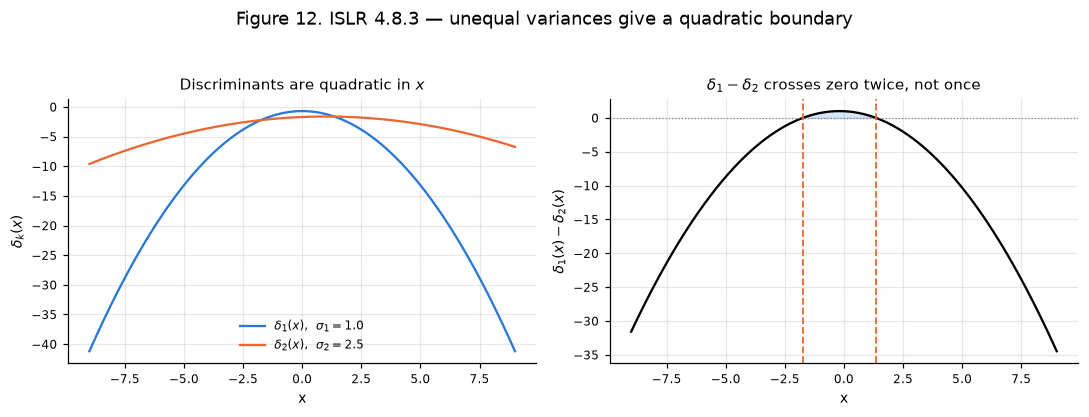

x^2 coefficient of the boundary A = -0.4200  (zero only if the variances are equal)
the boundary has 2 cut points: [-1.7424  1.3614]


In [26]:
mu1, sd1, pi1 = 0.0, 1.0, 0.5
mu2, sd2, pi2 = 1.0, 2.5, 0.5
xs = np.linspace(-9, 9, 800)


def delta(x, mu, sd, prior):
    return -(x - mu) ** 2 / (2 * sd ** 2) - np.log(sd) + np.log(prior)


d1, d2 = delta(xs, mu1, sd1, pi1), delta(xs, mu2, sd2, pi2)
A = 1 / (2 * sd2 ** 2) - 1 / (2 * sd1 ** 2)
Bc = mu1 / sd1 ** 2 - mu2 / sd2 ** 2
Cc = (-mu1 ** 2 / (2 * sd1 ** 2) - np.log(sd1) + np.log(pi1)) - \
     (-mu2 ** 2 / (2 * sd2 ** 2) - np.log(sd2) + np.log(pi2))
roots = np.roots([A, Bc, Cc])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].plot(xs, d1, color=BLUE, label=r"$\delta_1(x)$,  $\sigma_1 = 1.0$")
axes[0].plot(xs, d2, color=ORANGE, label=r"$\delta_2(x)$,  $\sigma_2 = 2.5$")
axes[0].set_title("Discriminants are quadratic in $x$")
axes[0].set_xlabel("x"); axes[0].set_ylabel(r"$\delta_k(x)$"); axes[0].legend(frameon=False)

axes[1].plot(xs, d1 - d2, color="black", lw=1.5)
axes[1].axhline(0, color="grey", lw=0.8, ls=":")
for r in np.sort(roots.real):
    axes[1].axvline(r, color=ORANGE, lw=1.2, ls="--")
axes[1].fill_between(xs, d1 - d2, 0, where=(d1 - d2) > 0, color=BLUE, alpha=0.18)
axes[1].set_title("$\\delta_1 - \\delta_2$ crosses zero twice, not once")
axes[1].set_xlabel("x"); axes[1].set_ylabel(r"$\delta_1(x) - \delta_2(x)$")
fig.suptitle("Figure 12. ISLR 4.8.3 — unequal variances give a quadratic boundary", y=1.04)
fig.tight_layout()
plt.show()

print(f"x^2 coefficient of the boundary A = {A:.4f}  (zero only if the variances are equal)")
print(f"the boundary has {len(np.unique(np.round(np.sort(roots.real), 6)))} cut points: "
      f"{np.sort(roots.real).round(4)}")

## 4. ISLR 4.8.7

> Suppose that we wish to predict whether a given stock will issue a dividend this year ("Yes" or
> "No") based on $X$, last year's percent profit. We examine a large number of companies and
> discover that the mean value of $X$ for companies that issued a dividend was $\bar{X} = 10$,
> while the mean for those that didn't was $\bar{X} = 0$. In addition, the variance of $X$ for
> these two sets of companies was $\hat\sigma^2 = 36$. Finally, 80% of companies issued dividends.
> Assuming that $X$ follows a normal distribution, predict the probability that a company will
> issue a dividend this year given that its percentage profit was $X = 4$ last year.

**Given.** $\mu_{\text{yes}} = 10$, $\mu_{\text{no}} = 0$, a *common* variance
$\sigma^2 = 36$ (so $\sigma = 6$), priors $\pi_{\text{yes}} = 0.8$ and $\pi_{\text{no}} = 0.2$,
and $x = 4$.

**Bayes' theorem** with normal class-conditional densities gives

$$p_{\text{yes}}(x) \;=\;
\frac{\pi_{\text{yes}}\,\dfrac{1}{\sqrt{2\pi\sigma^2}}\exp\!\left(-\dfrac{(x-\mu_{\text{yes}})^2}{2\sigma^2}\right)}
     {\pi_{\text{yes}}\,\dfrac{1}{\sqrt{2\pi\sigma^2}}\exp\!\left(-\dfrac{(x-\mu_{\text{yes}})^2}{2\sigma^2}\right)
      + \pi_{\text{no}}\,\dfrac{1}{\sqrt{2\pi\sigma^2}}\exp\!\left(-\dfrac{(x-\mu_{\text{no}})^2}{2\sigma^2}\right)}.$$

Because the two variances are equal, the factor $1/\sqrt{2\pi\sigma^2}$ is common to every term
and **cancels**:

$$p_{\text{yes}}(4) \;=\;
\frac{0.8\,e^{-(4-10)^2/72}}{0.8\,e^{-(4-10)^2/72} \;+\; 0.2\,e^{-(4-0)^2/72}}
\;=\; \frac{0.8\,e^{-1/2}}{0.8\,e^{-1/2} + 0.2\,e^{-2/9}}.$$

Evaluating the two exponentials, $e^{-0.5} = 0.606531$ and $e^{-0.222222} = 0.800737$:

$$p_{\text{yes}}(4) \;=\; \frac{0.8 \times 0.606531}{0.8 \times 0.606531 + 0.2 \times 0.800737}
\;=\; \frac{0.485225}{0.485225 + 0.160147}
\;=\; \frac{0.485225}{0.645372} \;=\; 0.7519.$$

**The probability that the company issues a dividend is $\approx 0.7519$, i.e. about 75.2%.**

A sanity check on the direction: the prior was 80%, and $x = 4$ sits closer to the *no* mean
($0$) than to the *yes* mean ($10$), so the evidence should pull the probability *down* from
80% — and it does, to 75.2%, a modest move because $\sigma = 6$ makes the two densities broad
and heavily overlapping.

In [27]:
mu_yes, mu_no, sigma2, prior_yes = 10.0, 0.0, 36.0, 0.8
x = 4.0

num = prior_yes * np.exp(-(x - mu_yes) ** 2 / (2 * sigma2))
den = num + (1 - prior_yes) * np.exp(-(x - mu_no) ** 2 / (2 * sigma2))
p_yes = num / den
print(f"exp(-(4-10)^2/72)  = {np.exp(-(x - mu_yes) ** 2 / (2 * sigma2)):.6f}")
print(f"exp(-(4-0)^2/72)   = {np.exp(-(x - mu_no) ** 2 / (2 * sigma2)):.6f}")
print(f"P(dividend | X = 4) = {p_yes:.6f}  ->  {100 * p_yes:.2f}%")

# Check against scikit-learn's LDA, which is the same model with a shared variance.
rng = np.random.default_rng(RANDOM_STATE)
n = 400_000
z = rng.random(n) < prior_yes
xs_sim = np.where(z, rng.normal(mu_yes, np.sqrt(sigma2), n), rng.normal(mu_no, np.sqrt(sigma2), n))
lda = LinearDiscriminantAnalysis().fit(xs_sim[:, None], z.astype(int))
print(f"LDA fitted on 400,000 simulated companies gives "
      f"{lda.predict_proba([[x]])[0, 1]:.4f}  (agrees to simulation error)")

exp(-(4-10)^2/72)  = 0.606531
exp(-(4-0)^2/72)   = 0.800737
P(dividend | X = 4) = 0.751852  ->  75.19%
LDA fitted on 400,000 simulated companies gives 0.7525  (agrees to simulation error)


## 5.1. Extra Practice ISLR 4.8.4

> When the number of features $p$ is large, there tends to be a deterioration in the performance
> of KNN and other *local* approaches that perform prediction using only observations that are
> *near* the test observation for which a prediction must be made. This phenomenon is known as
> the *curse of dimensionality* [...]

**(a) $p = 1$, $X \sim \text{Uniform}[0, 1]$, using observations within 10% of the range of $X$
closest to the test point. On average, what fraction of the available observations will we use?**

For a test point $x \in [0.05, 0.95]$ the interval $[x - 0.05,\, x + 0.05]$ lies entirely inside
$[0, 1]$ and contains a fraction 0.10 of the observations. Near the edges the interval is clipped.
Averaging over $x \sim \text{Uniform}[0,1]$:

$$\int_0^{0.05}\!\!(x + 0.05)\,dx \;+\; \int_{0.05}^{0.95}\!\!0.1\,dx \;+\; \int_{0.95}^{1}\!\!(1.05 - x)\,dx
\;=\; 0.00375 + 0.09 + 0.00375 \;=\; 0.0975.$$

**On average 9.75% of the observations are used** (10% if the boundary effect is ignored, as it
usually is).

**(b) $p = 2$, both features uniform, within 10% of the range of *each*.**

The two features are independent, so the fractions multiply:
$0.0975^2 = 0.00951$, i.e. **about 0.95%** (1% ignoring boundaries).

**(c) $p = 100$, within 10% of the range of each feature.**

$0.0975^{100} \approx 7.9 \times 10^{-102}$ — about $10^{-100}$, i.e. **essentially zero**. With a
data set of any conceivable size, *no* training observation falls inside that neighbourhood.

**(d) What does (a)-(c) imply about KNN when $p$ is large?**

The fraction of observations in a fixed-width neighbourhood shrinks **exponentially** in $p$:
$0.1^p$. So for large $p$ there are essentially **no training observations near any given test
observation**. A local method such as KNN must then either use a neighbourhood containing nothing
— making prediction impossible — or reach out to "neighbours" that are in fact very far away, in
which case the averaging is no longer local and the prediction is badly biased. Since KNN's whole
premise is that $f(x)$ is roughly constant over the neighbourhood, that premise fails and
performance deteriorates. Sample size cannot rescue this: to keep a 10% neighbourhood populated
as in $p = 1$ would need $n$ to grow like $10^{p}$.

**(e) Side length of a $p$-dimensional hypercube containing, on average, 10% of the training
observations, for $p = 1, 2, 100$.**

A cube of side $\ell$ centred on the test point contains a fraction $\ell^p$ of a uniform
distribution on $[0,1]^p$, so $\ell^p = 0.1$ and $\ell = 0.1^{1/p}$:

| $p$ | side length $\ell = 0.1^{1/p}$ | fraction of each feature's range spanned |
| --- | --- | --- |
| 1 | $0.1$ | 10% |
| 2 | $0.1^{1/2} \approx 0.3162$ | 31.6% |
| 100 | $0.1^{1/100} \approx 0.9772$ | 97.7% |

**Comment.** At $p = 100$ the "local" neighbourhood has to span **97.7% of the entire range of
every single feature** to capture a tenth of the data. It is not local in any meaningful sense —
it is almost the whole feature space. This is the geometric heart of the curse of dimensionality:
in high dimensions nearly all of the volume of a cube sits near its surface, so almost every point
is far from every other point, and the notion of a "nearest neighbour" stops carrying information.

     fraction used (0.1^p)  with the edge correction (0.0975^p)  side length for 10% (0.1^(1/p))
p                                                                                               
1                      0.1                               0.0975                              0.1
2                     0.01                             0.009506                           0.3162
3                    0.001                            0.0009269                           0.4642
5                    1e-05                            8.811e-06                            0.631
10                   1e-10                            7.763e-11                           0.7943
20                   1e-20                            6.027e-21                           0.8913
50                   1e-50                             2.82e-51                            0.955
100                 1e-100                           7.952e-102                           0.9772


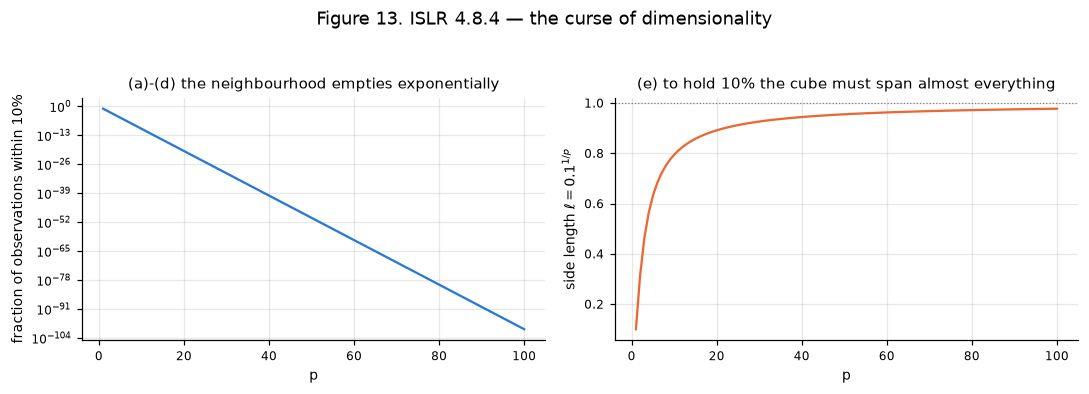

In [28]:
p_values = np.array([1, 2, 3, 5, 10, 20, 50, 100])
table = pd.DataFrame({
    "p": p_values,
    "fraction used (0.1^p)": 0.1 ** p_values,
    "with the edge correction (0.0975^p)": 0.0975 ** p_values,
    "side length for 10% (0.1^(1/p))": 0.1 ** (1 / p_values),
}).set_index("p")
print(table.to_string(float_format=lambda v: f"{v:.4g}"))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
pp = np.arange(1, 101)
axes[0].semilogy(pp, 0.1 ** pp, color=BLUE)
axes[0].set_xlabel("p"); axes[0].set_ylabel("fraction of observations within 10%")
axes[0].set_title("(a)-(d) the neighbourhood empties exponentially")
axes[1].plot(pp, 0.1 ** (1 / pp), color=ORANGE)
axes[1].axhline(1.0, color="grey", lw=0.8, ls=":")
axes[1].set_xlabel("p"); axes[1].set_ylabel(r"side length $\ell = 0.1^{1/p}$")
axes[1].set_title("(e) to hold 10% the cube must span almost everything")
fig.suptitle("Figure 13. ISLR 4.8.4 — the curse of dimensionality", y=1.04)
fig.tight_layout()
plt.show()

## 5.2. Extra Practice ISLR 4.8.9

> This problem has to do with *odds*.

The odds corresponding to a probability $p$ are $\text{odds} = \dfrac{p}{1 - p}$, and inverting
that relation gives $p = \dfrac{\text{odds}}{1 + \text{odds}}$.

**(a) On average, what fraction of people with an odds of 0.37 of defaulting on their credit card
payment will in fact default?**

$$p \;=\; \frac{0.37}{1 + 0.37} \;=\; \frac{0.37}{1.37} \;=\; 0.2701.$$

**About 27% of them will default.**

**(b) Suppose that an individual has a 16% chance of defaulting on her credit card payment. What
are the odds that she will default?**

$$\text{odds} \;=\; \frac{0.16}{1 - 0.16} \;=\; \frac{0.16}{0.84} \;=\; 0.1905.$$

**The odds are about 0.19** (roughly 0.19 to 1, or about 19 defaults for every 100 non-defaults).

In [29]:
odds_a = 0.37
p_a = odds_a / (1 + odds_a)
p_b = 0.16
odds_b = p_b / (1 - p_b)
print(f"(a) odds = {odds_a}       ->  probability = {p_a:.4f}  ({100 * p_a:.2f}%)")
print(f"(b) probability = {p_b}   ->  odds        = {odds_b:.4f}")
print(f"\nround trip check: p -> odds -> p = {(odds_b / (1 + odds_b)):.4f}")

(a) odds = 0.37       ->  probability = 0.2701  (27.01%)
(b) probability = 0.16   ->  odds        = 0.1905

round trip check: p -> odds -> p = 0.1600


## References

- Palumbo, F., Gallicchio, C., Pucci, R., Micheli, A. (2016). *Human activity recognition using
  multisensor data fusion based on Reservoir Computing.* Journal of Ambient Intelligence and
  Smart Environments — the source of the AReM data set.
- UCI Machine Learning Repository: [Activity Recognition system based on Multisensor data fusion (AReM)](https://archive.ics.uci.edu/ml/datasets/Activity+Recognition+system+based+on+Multisensor+data+fusion+%28AReM%29)
- James, G., Witten, D., Hastie, T., Tibshirani, R. *An Introduction to Statistical Learning*,
  2nd ed. — Section 4.4 (LDA/QDA), Section 4.6.3, Section 5.1 (the right way to cross-validate),
  and exercises 4.8.3, 4.8.4, 4.8.7, 4.8.9.
- Hastie, T., Tibshirani, R., Friedman, J. *The Elements of Statistical Learning*, 2nd ed. —
  Section 7.10.2, *"The Wrong and Right Way to Do Cross-validation"*, which is the argument
  applied in 2(a)iii.
- Albert, A., Anderson, J. A. (1984). *On the existence of maximum likelihood estimates in
  logistic regression models.* Biometrika 71(1), 1-10 — the formal treatment of the complete
  separation found in 2(a)vi.
- King, G., Zeng, L. (2001). *Logistic Regression in Rare Events Data.* Political Analysis 9(2),
  137-163 — the intercept correction used for case-control sampling in 2(a)vii.
- Fawcett, T. (2006). *An introduction to ROC analysis.* Pattern Recognition Letters 27(8),
  861-874 — one-vs-rest ROC curves and micro/macro averaging for multiclass problems.
- scikit-learn documentation:
  [RFE](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.RFE.html),
  [LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html),
  [Naive Bayes](https://scikit-learn.org/stable/modules/naive_bayes.html),
  [ROC for multiclass](https://scikit-learn.org/stable/auto_examples/model_selection/plot_roc.html)